# Task 4 – Teil 2: Unterlagertes Niederspannungs-Ortsnetz

**Ziel:** Als Ortsnetz wird das Niederspannungs-Benchmarknetz von CIGRE (`create_cigre_network_lv`) verwendet. Es wird zunächst allein berechnet (Basisdaten). Anschließend wird über eine Sensitivitätsanalyse der 20-kV-Bus des CIGRE-MV-Netzes bestimmt, an den das Ortsnetz angeschlossen wird.

## Vorgehen zur Wahl des Anschlussbusses

**Schritt 1 – Vorbelastung des MV-Netzes ohne Ortsnetz.** Zuerst wird untersucht, welche Teile des CIGRE-MV-Netzes schon ohne das Ortsnetz belastet sind (niedrige Spannungen, hohe Leitungs- und Trafoauslastungen). Die beiden Transformatoren 110/20 kV haben keinen Stufenschalter und werden auch in den folgenden Aufgaben nicht zu regelbaren Transformatoren. Es wäre deshalb unklug, einen ohnehin belasteten Netzteil weiter zu belasten.

**Schritt 2 – Ausschluss.** Das Ortsnetz wird nacheinander an jeden 20-kV-Bus (Bus 1 bis Bus 14) angeschlossen und über 12 typische Wochen simuliert. Ausgeschlossen wird jeder Anschlussbus, bei dem in mindestens einer Stunde

- ein Bus (MV oder LV) unter 0,90 pu fällt oder
- eine Leitung oder ein Transformator über 100 % ausgelastet ist.

*Begründung:* Man könnte argumentieren, dass sich ein solcher Engpass durch Schalthandlungen beheben lässt, z. B. durch Schließen von S1, das das Netz deutlich entlastet (Teil 1). Simuliert wird hier aber der **Normalbetrieb**. Die Simulation enthält keine unvorhersehbaren Situationen, in denen plötzlich deutlich mehr Leistung verbraucht wird und deshalb eingegriffen werden muss. Es wäre unklug, eine so starke Maßnahme, die zugleich die einzige verfügbare ist, schon fest in den Normalbetrieb einzuplanen. Außerdem wäre das Netz dann darauf angewiesen, dass beide Transformatoren ständig in Betrieb sind: Mit geschlossenem S1 würde der Ausfall eines Transformators sofort zu einer Versorgungsunterbrechung führen, weil der verbleibende Transformator das gesamte Netz nicht tragen kann (siehe Trafo-Ausfall in Task 3).

**Schritt 3 – Auswahl.** Unter den verbleibenden Anschlussbussen wird die Simulation mit der **höchsten niedrigsten Spannung** und der **niedrigsten höchsten Auslastung** von Leitungen und Transformatoren gewählt.

*Begründung:* Simuliert wird der Normalbetrieb ohne unvorhersehbare Situationen. Deshalb soll ein Anschlusspunkt gewählt werden, an dem im Normalbetrieb möglichst wenig geregelt werden muss und die meiste Reserve für unvorhergesehene Situationen bleibt.

**Aufbau des Notebooks:**

1. Das CIGRE-LV-Netz: Topologie, Betriebsmittel, thermische Grenzen, Lasten und statischer Lastfluss (Basisdaten)
2. Schritt 1: Vorbelastung des MV-Netzes ohne Ortsnetz
3. Zusammenführen von MV- und LV-Netz
4. Zeitreihe für jeden Anschlussbus
5. Schritt 2: Ausschluss
6. Schritt 3: Auswahl des Anschlussbusses
7. Ergebnis
8. Anhang: Netzpläne aller Anschlussvarianten

Das MV-Netz ist das Referenzszenario aus `Task4-1_Baseline.ipynb` (CIGRE-MV ohne DER, alle Trennschalter offen).

## Importe

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.networks as pn

import simulation as sim
import szenarien as sz
import lvnetz
import netplan
import plots
from elements import Diagram, Profile
from profiles import Month

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=plt.cm.tab20.colors)

# Zeitreihen nur neu rechnen, wenn sich Netz, Einstellungen oder Daten geändert haben
sim.ONLY_RUN_IF_CHANGED = True

def baseline_net():
    """Unverändertes CIGRE-MV-Netz ohne dezentrale Erzeuger (Referenz aus Teil 1)."""
    return pn.create_cigre_network_mv(with_der=False)

MV_BUSES = [f"Bus {i}" for i in range(1, 15)]       # mögliche Anschlussbusse (20 kV, ohne Bus 0 = 110 kV)
V_MIN, V_MAX = 0.90, 1.10                           # Arbeitsgrenzen

Neues Modul `lvnetz.py`: erzeugt das CIGRE-LV-Netz mit den thermischen Grenzströmen und Koordinaten für den gemeinsamen Netzplan, hängt es an einen MV-Bus an, ordnet den LV-Lasten Profile zu und berechnet die Kennwerte getrennt nach MV und LV.

## 1 Das CIGRE-LV-Netz (Basisdaten)

![CIGRE-MV-Netz ohne dezentrale Erzeuger](cigre_network_lv.png)

Das CIGRE-LV-Benchmarknetz [13] besteht aus drei Teilnetzen, die je über einen eigenen Ortsnetztransformator 20/0,4 kV an der 20-kV-Sammelschiene `Bus 0` hängen:

| Teilnetz | Bezeichnung | Ausführung | Ortsnetztrafo |
|---|---|---|---|
| R | Wohngebiet (*residential*) | Kabel (UG1, UG3) | Trafo R0-R1, 0,50 MVA |
| I | Industrie (*industrial*) | Kabel (UG2) | Trafo I0-I1, 0,15 MVA |
| C | Gewerbe (*commercial*) | Freileitung (OH1–OH3) | Trafo C0-C1, 0,30 MVA |

Die drei Teilnetze sind über die Leistungsschalter S1–S3 (Bus–Bus) mit `Bus 0` verbunden. Als Slack dient ein externes Netz an `Bus 0` mit 1,0 pu. Alle Teilnetze werden strahlenförmig betrieben.

In [2]:
lv = lvnetz.lv_net_alone()
lv

This pandapower network includes the following parameter tables:
   - bus (44 elements)
   - load (15 elements)
   - switch (3 elements)
   - ext_grid (1 element)
   - line (37 elements)
   - trafo (3 elements)

In [3]:
lv_bus = lv.bus[["name", "vn_kv"]].copy()
lv_bus["Teilnetz"] = lv_bus.name.str.extract(r"Bus ([RIC])")[0].fillna("Sammelschiene")
print(lv_bus.groupby(["Teilnetz", "vn_kv"]).size().rename("Anzahl Busse").to_string())

Teilnetz       vn_kv
C              0.4      20
               20.0      1
I              0.4       2
               20.0      1
R              0.4      18
               20.0      1
Sammelschiene  20.0      1


**Ortsnetztransformatoren.** Die Transformatoren haben eine Stufenstellung `tap_pos = 0`, aber keinen Stellbereich. Ein regelbarer Stufenschalter wird erst in Teil 3 ergänzt.

In [4]:
tr = lv.trafo[["name", "sn_mva", "vn_hv_kv", "vn_lv_kv", "vk_percent", "vkr_percent", "pfe_kw",
               "i0_percent", "shift_degree", "tap_pos", "tap_min", "tap_max", "tap_step_percent"]].set_index("name")
tr["I_n US [A]"] = lv.trafo.sn_mva.values / (np.sqrt(3) * lv.trafo.vn_lv_kv.values) * 1000
tr

,sn_mva,vn_hv_kv,vn_lv_kv,vk_percent,vkr_percent,pfe_kw,i0_percent,shift_degree,tap_pos,tap_min,tap_max,tap_step_percent,I_n US [A]
name,,,,,,,,,,,,,
Trafo R0-R1,0.50,20.0,0.4,4.123106,1.000000,0.0,0.0,30.0,0.0,NaN,NaN,NaN,721.687836
Trafo I0-I1,0.15,20.0,0.4,4.126896,1.003125,0.0,0.0,30.0,0.0,NaN,NaN,NaN,216.506351
Trafo C0-C1,0.30,20.0,0.4,4.115529,0.993750,0.0,0.0,30.0,0.0,NaN,NaN,NaN,433.012702


### 1.1 Leitungstypen und thermische Grenzen

In pandapower ist für alle LV-Leitungen `max_i_ka = 1,0 kA` eingetragen. Das ist ein Platzhalter und keine thermische Grenze. Die Grenzströme werden deshalb aus der Tabelle der CIGRE-LV-Leitungstypen in [18] übernommen (Spalte *Rated Current*) und mit `lvnetz.apply_line_limits()` gesetzt:

In [5]:
lvnetz.LINE_TYPE_DATA

,Querschnitt [mm²],R Phase [Ω/km],L Phase [mH/km],R Neutral [Ω/km],L Neutral [mH/km],I_r [A]
Typ,,,,,,
UG1,240,0.163,0.433,0.490,1.50,430
UG2,150,0.266,0.481,0.733,1.81,325
UG3,120,0.326,0.503,0.860,2.01,290
UG4,25,1.540,0.656,2.330,4.63,120
UG5,35,1.110,0.621,1.930,4.03,145
UG6,70,0.569,0.554,1.290,2.75,215
OH1,50,0.387,0.939,0.689,1.50,172
OH2,35,0.524,0.977,0.838,1.56,145
OH3,16,1.150,1.050,1.840,1.69,93


**Vergleich der Leitungsparameter.** Die Reaktanz des Phasenleiters folgt aus der Induktivität mit $X' = 2 \pi f L'$ ($f$ = 50 Hz). Die Widerstände und Reaktanzen der pandapower-Typen weichen für einige Typen deutlich von den Phasenleiterwerten in [18] ab (z. B. UG3, OH2, OH3). pandapower verwendet für den symmetrischen Lastfluss Mitsystemwerte aus der Umsetzung von [13]; die Tabelle in [18] nennt die Werte von Phasen- und Neutralleiter einzeln. Für die Lastflüsse werden die **pandapower-Impedanzen beibehalten**; aus [18] werden nur die Grenzströme übernommen.

In [6]:
used = sorted(lv.line.std_type.unique())
vgl = pd.DataFrame({
    "R' pandapower [Ω/km]": [lv.std_types["line"][t]["r_ohm_per_km"] for t in used],
    "R' Phase [18] [Ω/km]": lvnetz.LINE_TYPE_DATA.loc[used, "R Phase [Ω/km]"].values,
    "X' pandapower [Ω/km]": [lv.std_types["line"][t]["x_ohm_per_km"] for t in used],
    "X' Phase [18] [Ω/km]": (2 * np.pi * 50 * lvnetz.LINE_TYPE_DATA.loc[used, "L Phase [mH/km]"] / 1000).values,
    "I_max pandapower [A]": [lv.std_types["line"][t]["max_i_ka"] * 1000 for t in used],
    "I_max verwendet [A]": lvnetz.LINE_TYPE_DATA.loc[used, "I_r [A]"].values,
    "Anzahl Leitungen": [int((lv.line.std_type == t).sum()) for t in used],
}, index=used)
plots.table(vgl, decimals=3)

,R' pandapower [Ω/km],R' Phase [18] [Ω/km],X' pandapower [Ω/km],X' Phase [18] [Ω/km],I_max pandapower [A],I_max verwendet [A],Anzahl Leitungen
OH1,0.492,0.387,0.285,0.295,1000.000,172.000,8.000
OH2,1.321,0.524,0.321,0.307,1000.000,145.000,4.000
OH3,2.017,1.150,0.334,0.330,1000.000,93.000,7.000
UG1,0.162,0.163,0.083,0.136,1000.000,430.000,9.000
UG2,0.265,0.266,0.082,0.151,1000.000,325.000,1.000
UG3,0.822,0.326,0.085,0.158,1000.000,290.000,8.000


**Lasten.** 15 Lasten mit zusammen 0,69 MW. Die Werte aus [13] werden wie im MV-Netz als Höchstleistung interpretiert.

In [7]:
ld = lv.load[["name", "bus", "p_mw", "q_mvar"]].copy()
ld["Bus"] = lv.bus.name.loc[ld.bus].values
ld["cos φ"] = ld.p_mw / np.hypot(ld.p_mw, ld.q_mvar)
ld["Teilnetz"] = ld.name.str.extract(r"Load ([RIC])")[0]
display(plots.table(ld.drop(columns="bus").set_index("name"), decimals=4))
ld.groupby("Teilnetz")[["p_mw", "q_mvar"]].sum().assign(Anzahl=ld.groupby("Teilnetz").size())

,p_mw,q_mvar,Bus,cos φ,Teilnetz
name,,,,,
Load R1,0.1900,0.0624,Bus R1,0.9500,R
Load R11,0.0143,0.0047,Bus R11,0.9500,R
Load R15,0.0494,0.0162,Bus R15,0.9500,R
Load R16,0.0522,0.0172,Bus R16,0.9500,R
Load R17,0.0333,0.0109,Bus R17,0.9500,R
Load R18,0.0447,0.0147,Bus R18,0.9500,R
Load I2,0.0850,0.0527,Bus I2,0.8500,I
Load C1,0.1080,0.0523,Bus C1,0.9000,C
Load C12,0.0180,0.0087,Bus C12,0.9000,C


,p_mw,q_mvar,Anzahl
Teilnetz,,,
C,0.2178,0.105485,8
I,0.0850,0.052678,1
R,0.3838,0.126149,6


### 1.2 Statischer Lastfluss des LV-Netzes allein

In [8]:
base_lv = sz.lastfluss(lv)
assert base_lv["converged"], "LV-Lastfluss nicht konvergiert"
print(f"Konvergiert: ja, {base_lv['iterations']} Iterationen")
base_lv["bilanz"].round(4).to_frame("Wert")

Konvergiert: ja, 3 Iterationen


,Wert
Last P [MW],0.6866
Erzeugung P [MW],0.0000
Bezug ext. Netz P [MW],0.7149
Bezug ext. Netz Q [Mvar],0.3188
Verluste Leitungen [MW],0.0218
Verluste Trafos [MW],0.0065
Verluste gesamt [MW],0.0283
Verluste [% der Last],4.1260


In [9]:
plots.table(base_lv["bus"], decimals=4)

,U_n [kV],vm_pu,U [kV],va_degree,P_einspeisung [MW]
Bus 0,20.0000,1.0000,20.0000,0.0000,0.7149
Bus R0,20.0000,1.0000,20.0000,0.0000,-0.0000
Bus R1,0.4000,0.9809,0.3924,-31.6919,-0.1900
Bus R2,0.4000,0.9722,0.3889,-31.7712,-0.0000
Bus R3,0.4000,0.9636,0.3854,-31.8519,-0.0000
Bus R4,0.4000,0.9556,0.3822,-31.9282,-0.0000
Bus R5,0.4000,0.9498,0.3799,-31.9831,-0.0000
Bus R6,0.4000,0.9440,0.3776,-32.0386,-0.0000
Bus R7,0.4000,0.9405,0.3762,-32.0722,-0.0000
Bus R8,0.4000,0.9370,0.3748,-32.1059,-0.0000


In [10]:
display(plots.table(base_lv["line"], decimals=4))
base_lv["trafo"].round(3)

,von,nach,p_from_mw,q_from_mvar,p_to_mw,i_ka,max_i_ka,loading_percent,pl_mw
Line R1-R2,Bus R1,Bus R2,0.2046,0.0678,-0.2029,0.3172,0.4300,73.7586,0.0017
Line R2-R3,Bus R2,Bus R3,0.2029,0.0670,-0.2012,0.3172,0.4300,73.7586,0.0017
Line R3-R4,Bus R3,Bus R4,0.1869,0.0614,-0.1854,0.2946,0.4300,68.5206,0.0015
Line R4-R5,Bus R4,Bus R5,0.1338,0.0442,-0.1330,0.2128,0.4300,49.4844,0.0008
Line R5-R6,Bus R5,Bus R6,0.1330,0.0438,-0.1322,0.2128,0.4300,49.4844,0.0008
Line R6-R7,Bus R6,Bus R7,0.0794,0.0261,-0.0792,0.1279,0.4300,29.7405,0.0003
Line R7-R8,Bus R7,Bus R8,0.0792,0.0260,-0.0789,0.1279,0.4300,29.7405,0.0003
Line R8-R9,Bus R8,Bus R9,0.0789,0.0259,-0.0786,0.1279,0.4300,29.7405,0.0003
Line R9-R10,Bus R9,Bus R10,0.0451,0.0148,-0.0450,0.0734,0.4300,17.0777,0.0001
Line R3-R11,Bus R3,Bus R11,0.0143,0.0047,-0.0142,0.0225,0.2900,7.7668,0.0000


,p_hv_mw,q_hv_mvar,p_lv_mw,loading_percent,pl_mw
Trafo R0-R1,0.398,0.145,-0.395,84.726,0.004
Trafo I0-I1,0.089,0.057,-0.089,70.662,0.001
Trafo C0-C1,0.227,0.117,-0.225,85.255,0.002


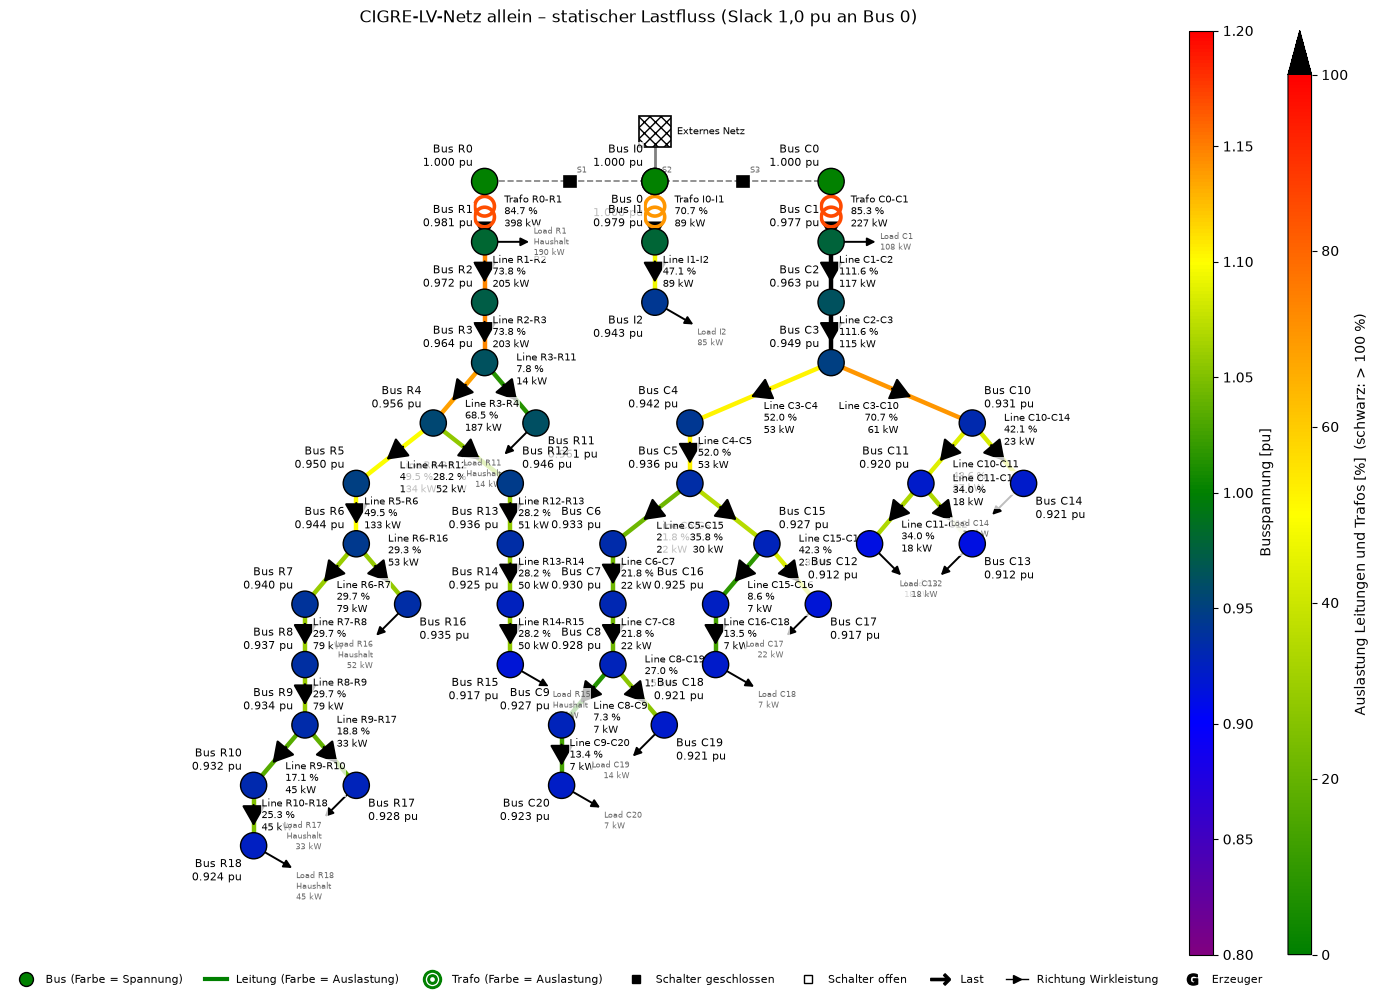

In [11]:
netplan.plot_static(lv, title="CIGRE-LV-Netz allein – statischer Lastfluss (Slack 1,0 pu an Bus 0)");

In [12]:
w, o = lvnetz.kennwerte_static(lv)
pd.DataFrame({"Wert": w.round(3), "Ort": o}).dropna()

,Wert,Ort
U min MS [pu],1.000,Bus 0
U max MS [pu],1.000,Bus 0
U min NS [pu],0.912,Bus C12
U max NS [pu],0.981,Bus R1
Winkel min MS [°],0.000,Bus 0
Winkel max MS [°],0.000,Bus 0
Winkel min NS [°],-32.160,Bus R10
Winkel max NS [°],-30.636,Bus I2
Leitung min NS [%],7.270,Line C8-C9
Leitung max NS [%],111.581,Line C2-C3


**Basisdaten LV-Netz (statisch, alle Lasten mit Bemessungsleistung, Slack 1,0 pu):**

- Der Lastfluss konvergiert in 3 Iterationen. Bei 0,687 MW Last bezieht das LV-Netz 0,715 MW. Die Verluste betragen 28 kW, das sind 4,1 % der Last und damit deutlich mehr als im MV-Netz (0,7 %), weil bei 0,4 kV für dieselbe Leistung ein 50-mal so großer Strom fließt.
- Die niedrigste Spannung liegt bei 0,912 pu am Ende des Gewerbe-Freileitungsnetzes (Bus C12).
- Mit den Grenzströmen aus [18] sind die ersten Abschnitte der Gewerbe-Freileitung (Line C1-C2 und Line C2-C3, Typ OH1, 172 A) mit 112 % **überlastet**. Über sie fließt die gesamte Last des Gewerbenetzes außer Load C1. Alle anderen Leitungen liegen darunter.
- Die Ortsnetztrafos sind zu 71 % (I), 85 % (R) und 85 % (C) ausgelastet.

## 2 Schritt 1: Vorbelastung des MV-Netzes ohne Ortsnetz

Grundlage ist die Referenz-Zeitreihe aus Teil 1 (`w4_baseline_000`: CIGRE-MV ohne DER, alle Trennschalter offen, 12 typische Wochen). Mit `sim.ONLY_RUN_IF_CHANGED = True` werden die gespeicherten Ergebnisse geladen.

In [13]:
ref = sim.init("w4_baseline", baseline_net(), overwrite=True, assignProfiles=True)
ref_ts = sz.zeitreihe_alle(ref, prefix="w4_baseline", keys=["000"])["000"]
ref_ts.summary()

18 Profile zugeordnet: HAUSHALT: 10, GEWERBE: 8
Simulation 'w4_baseline_000': unverändert seit dem Lauf vom 2026-10-28T14:44:03 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).


Zeitschritte                                                         2016
konvergiert                                                          2016
U min [pu]                                                         0.9487
U max [pu]                                                           1.03
Stunden U < 0.9                                                         0
Stunden U > 1.1                                                         0
Leitung max [%]                                                      78.6
Stunden Leitung > 100 %                                                 0
Trafo max [%]                                                        82.7
Stunden Trafo > 100 %                                                   0
Stunden Rückspeisung ins vorgelagerte Netz                              0
max. Rückspeisung [MW]                                                0.0
Energie Lasten [MWh]                                              43722.0
Energie Erzeuger [MWh]                

### 2.1 Niedrigste Spannung je Bus und Monat

In [14]:
plots.table(sz.monatstabelle(ref_ts, "Spannung", "min"), decimals=3, cmap="RdYlGn", vmin=0.92, vmax=1.03)

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Spannung min [pu],,,,,,,,,,,,
Bus 0,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030
Bus 1,1.002,1.002,1.006,1.008,1.011,1.012,1.012,1.013,1.011,1.008,1.004,1.002
Bus 2,0.984,0.984,0.990,0.993,0.999,1.000,1.000,1.001,0.998,0.993,0.986,0.984
Bus 3,0.955,0.956,0.964,0.970,0.980,0.981,0.981,0.983,0.978,0.969,0.959,0.956
Bus 4,0.953,0.954,0.963,0.968,0.978,0.979,0.980,0.981,0.976,0.968,0.957,0.954
Bus 5,0.952,0.953,0.962,0.967,0.978,0.979,0.979,0.981,0.975,0.967,0.956,0.953
Bus 6,0.950,0.952,0.961,0.966,0.977,0.978,0.978,0.980,0.974,0.966,0.955,0.951
Bus 7,0.950,0.952,0.961,0.966,0.977,0.978,0.979,0.980,0.975,0.966,0.955,0.951
Bus 8,0.951,0.952,0.961,0.966,0.977,0.978,0.979,0.980,0.975,0.966,0.955,0.952


### 2.2 Höchste Leitungsauslastung je Leitung und Monat

In [15]:
plots.table(sz.monatstabelle(ref_ts, "Leitung", "max"), decimals=1, cmap="YlOrRd", vmin=0, vmax=100)

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Leitung max [%],,,,,,,,,,,,
Line 1-2,78.2,77.4,69.0,64.8,54.8,53.5,53.0,51.8,56.9,64.2,74.7,76.6
Line 2-3,78.6,77.7,69.4,65.2,55.2,53.9,53.4,52.1,57.3,64.6,75.1,77.1
Line 3-4,36.6,36.1,31.5,30.1,25.2,24.2,24.4,23.8,26.4,29.9,34.7,34.9
Line 4-5,27.3,26.9,23.6,22.5,18.8,18.1,18.2,17.8,19.7,22.4,25.9,26.1
Line 5-6,11.8,11.6,10.2,9.7,8.1,7.8,7.9,7.7,8.5,9.7,11.2,11.3
Line 7-8,1.9,1.8,1.8,1.6,1.5,1.5,1.4,1.4,1.5,1.6,1.8,1.8
Line 8-9,24.5,23.9,22.9,21.5,19.7,19.3,18.8,18.8,19.3,20.7,23.8,24.6
Line 9-10,17.8,17.6,15.3,14.7,12.3,11.9,11.9,11.6,12.9,14.6,16.9,17.0
Line 10-11,7.1,7.0,6.1,5.8,4.9,4.7,4.7,4.6,5.1,5.8,6.7,6.8


### 2.3 Höchste Trafoauslastung je Trafo und Monat

In [16]:
plots.table(sz.monatstabelle(ref_ts, "Trafo", "max"), decimals=1, cmap="YlOrRd", vmin=0, vmax=100)

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Trafo max [%],,,,,,,,,,,,
Trafo 0-1,82.7,81.8,73.6,69.2,59.1,57.8,57.2,56.0,61.2,68.7,79.2,81.4
Trafo 0-12,68.4,67.5,61.1,57.3,49.1,48.2,47.6,46.6,50.8,57.2,65.4,67.7


### 2.4 Stunden mit niedriger Spannung, Bus für Bus

Anzahl der Stunden (von 2016) unter 0,90 pu (Arbeitsgrenze) und unter 0,95 pu sowie die niedrigste Spannung mit Zeitpunkt. Ohne Ortsnetz gibt es nur MS-Busse.

In [17]:
plots.table(sz.stunden_je_bus(ref_ts), decimals=3, int_cols=["Stunden U < 0,90", "Stunden U < 0,95"])

,"Stunden U < 0,90","Stunden U < 0,95",U min [pu],Zeitpunkt U min
Bus 0,0,0,1.030,Mon 06.01. 00:00
Bus 1,0,0,1.002,Fri 10.01. 18:00
Bus 2,0,0,0.984,Fri 10.01. 18:00
Bus 3,0,0,0.955,Fri 10.01. 18:00
Bus 4,0,0,0.953,Fri 10.01. 18:00
Bus 5,0,0,0.952,Fri 10.01. 18:00
Bus 6,0,0,0.950,Fri 10.01. 18:00
Bus 7,0,0,0.950,Fri 10.01. 18:00
Bus 8,0,0,0.951,Fri 10.01. 18:00
Bus 9,0,2,0.950,Fri 10.01. 18:00


### 2.5 Netzpläne: niedrigste Spannung und höchste Auslastung

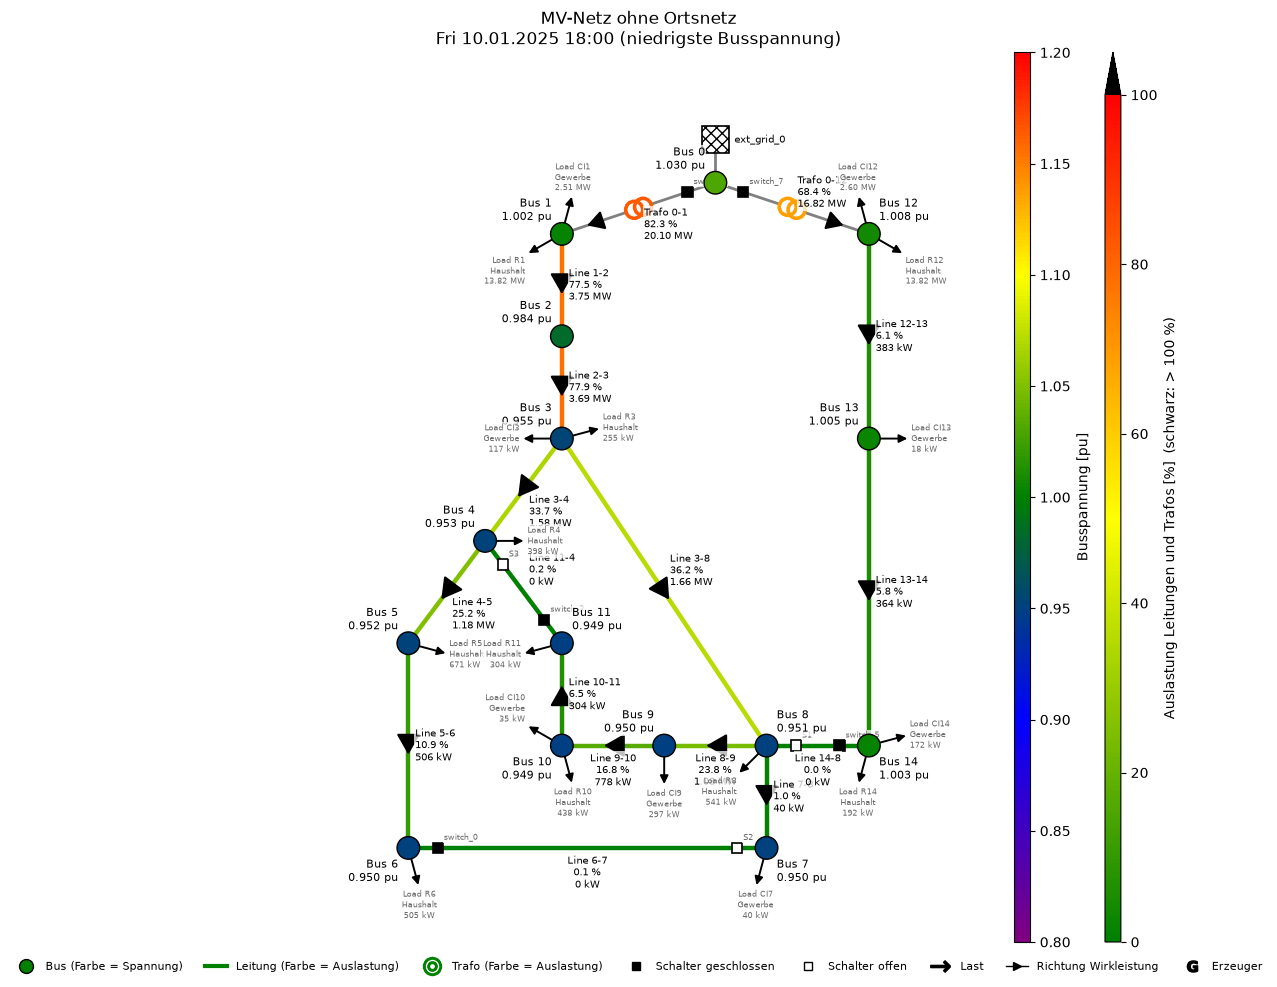

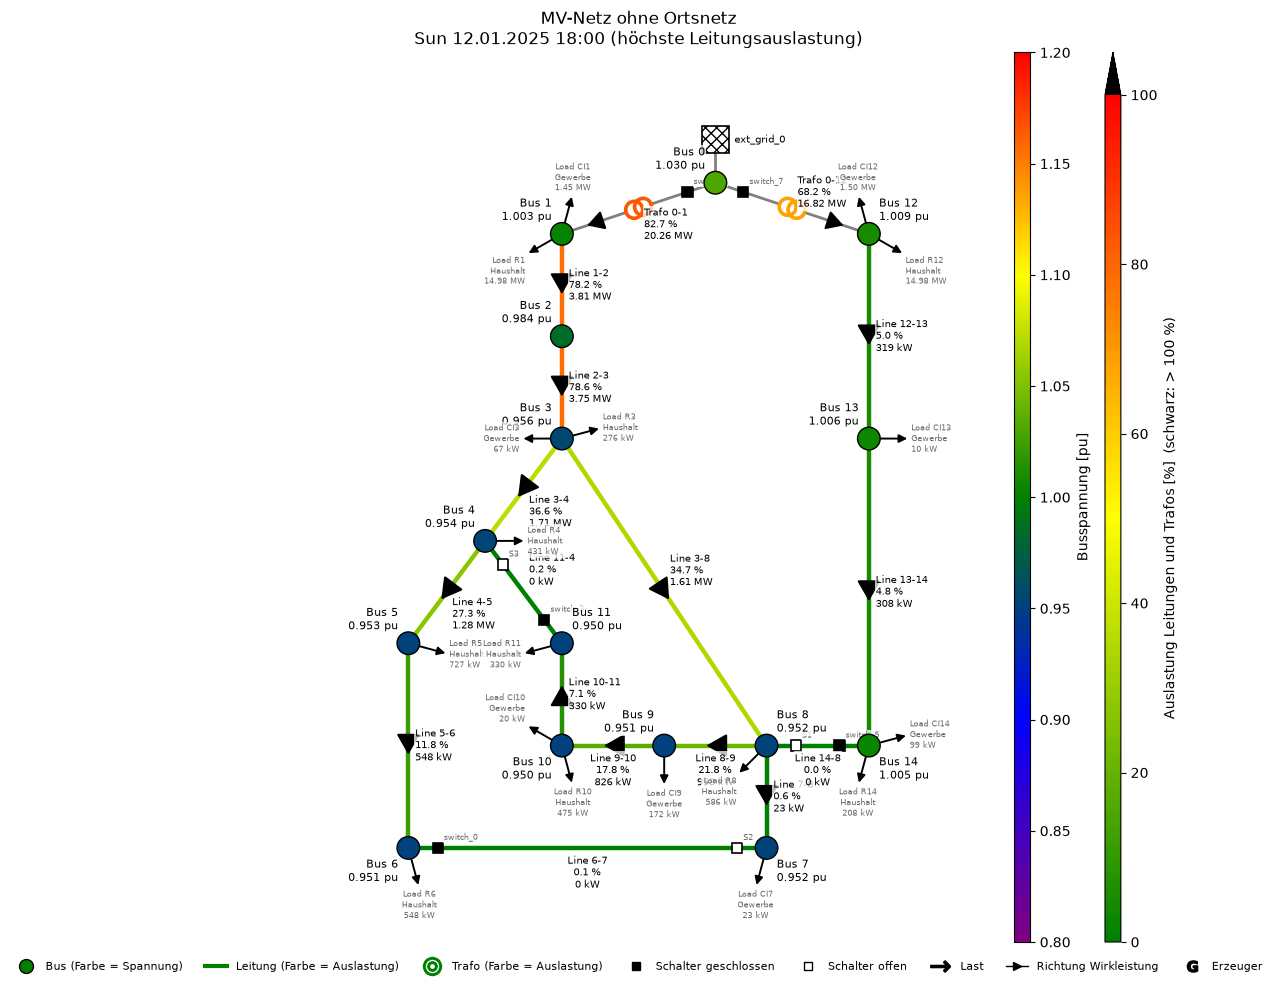

In [18]:
ref_ts.createDiagram(Diagram.NETWORK, time=["min", "max_loading"], title="MV-Netz ohne Ortsnetz")

**Befund Schritt 1 (MV-Netz ohne Ortsnetz):**

- **Spannung:** In keiner Stunde fällt ein Bus unter 0,90 pu. Abgang 1 ist aber deutlich vorbelastet: Ab Bus 3 sinkt die Spannung zur Abendspitze im Januar (Fr 10.01. 18:00) auf 0,949 bis 0,955 pu, Bus 9 bis Bus 11 liegen 2 bis 8 Stunden unter 0,95 pu. Abgang 2 (Bus 12 bis Bus 14) bleibt das ganze Jahr über 1,00 pu, ebenso Bus 1 an der Trafo-Sammelschiene.
- **Leitungen:** Line 1-2 und Line 2-3 sind im Winter bis 78,6 % ausgelastet, im Sommer etwa 52 %. Alle übrigen Kabel in Abgang 1 bleiben unter 37 %, die Freileitungen in Abgang 2 unter 8 %.
- **Transformatoren:** Trafo 0-1 (Abgang 1) erreicht im Januar 82,7 %, Trafo 0-12 (Abgang 2) 68,4 %.
- **Folgerung:** Der belastete Teil des Netzes ist Abgang 1 mit Trafo 0-1, Line 1-2, Line 2-3 und den Bussen ab Bus 3. Abgang 2 und Trafo 0-12 haben die größte Reserve bei Spannung und Auslastung.

## 3 Zusammenführen von MV- und LV-Netz

Das LV-Netz wird mit `Simulation.attachNetwork()` angeschlossen:

1. **Nennspannung prüfen:** Der Slack-Bus des LV-Netzes (`Bus 0`, 20 kV) und der MV-Anschlussbus müssen dieselbe Nennspannung haben, sonst bricht die Funktion ab.
2. **Externes Netz entfernen:** Das LV-Netz wird künftig aus dem MV-Netz versorgt, sein externes Netz entfällt.
3. **Namen eindeutig machen:** Alle Elemente des LV-Netzes erhalten das Präfix `LV` (z. B. `LV Bus R1`, `LV S1`, `LV Load R1`). Damit gibt es keine Namensgleichheit mit dem MV-Netz, z. B. bei `Load R1` oder den Schaltern `S1`–`S3`.
4. **Indizes eindeutig machen:** `pandapower.toolbox.merge_nets` hängt die Tabellen aneinander und nummeriert die Indizes des LV-Netzes neu.
5. **Busse vereinigen:** `fuse_buses` vereinigt `LV Bus 0` mit dem MV-Anschlussbus. Alle Elemente an `LV Bus 0` hängen danach am MV-Bus.
6. **Profile zuordnen:** `LV Load R…` erhält H25 (Wohngebiet), `LV Load I…` und `LV Load C…` erhalten G25 (Industrie und Gewerbe; ein eigenes Industrieprofil gibt es bei den BDEW-Standardlastprofilen nicht). Die Skalierung erfolgt wie im MV-Netz über die Jahreshöchstleistung (`p_mw` aus [13]).

Beispiel: Anschluss an Bus 5, mit Prüfung der Indizes, Namen und der Leistungsbilanz.

In [19]:
net_mv = baseline_net()
sim._ensure_names(net_mv)
sim._ensure_profile_columns(net_mv)
demo = sim.Simulation("demo", net_mv)
demo.attachNetwork(lvnetz.lv_net(), "Bus 5", prefix=lvnetz.PREFIX)
n = demo.net

pruefung = pd.DataFrame({
    "MV allein": [len(net_mv[t]) for t in ["bus", "line", "trafo", "switch", "load", "ext_grid"]],
    "LV allein": [len(lv[t]) for t in ["bus", "line", "trafo", "switch", "load", "ext_grid"]],
    "zusammen": [len(n[t]) for t in ["bus", "line", "trafo", "switch", "load", "ext_grid"]],
}, index=["bus", "line", "trafo", "switch", "load", "ext_grid"])
pruefung["Erwartung"] = pruefung["MV allein"] + pruefung["LV allein"] - pd.Series({"bus": 1, "ext_grid": 1}).reindex(pruefung.index).fillna(0).astype(int)
display(pruefung)
print("Indizes eindeutig:", all(n[t].index.is_unique for t in ["bus", "line", "trafo", "switch", "load"]))
print("Namen eindeutig:  ", pd.concat([n[t]["name"] for t in ["bus", "line", "trafo", "switch", "load"]]).is_unique)
print("Nennspannungen:   ", dict(n.bus.vn_kv.value_counts().sort_index()))
print(f"Last gesamt: {n.load.p_mw.sum():.4f} MW = MV {net_mv.load.p_mw.sum():.4f} MW + LV {lv.load.p_mw.sum():.4f} MW")
ok = sz.lastfluss(n)
b = ok["bilanz"]
print(f"Konvergiert: {ok['converged']} | Bezug ext. Netz {b['Bezug ext. Netz P [MW]']:.4f} MW = "
      f"Last {b['Last P [MW]']:.4f} MW + Verluste {b['Verluste gesamt [MW]']:.4f} MW")

101 Elemente angehängt an 'Bus 5' (Bus 'LV Bus 0' mit 'Bus 5' vereinigt).


,MV allein,LV allein,zusammen,Erwartung
bus,15,44,58,58
line,15,37,52,52
trafo,2,3,5,5
switch,8,3,11,11
load,18,15,33,33
ext_grid,1,1,1,1


Indizes eindeutig: True
Namen eindeutig:   True
Nennspannungen:    {0.4: np.int64(40), 20.0: np.int64(17), 110.0: np.int64(1)}
Last gesamt: 45.4287 MW = MV 44.7421 MW + LV 0.6866 MW
Konvergiert: True | Bezug ext. Netz 45.8697 MW = Last 45.4287 MW + Verluste 0.4410 MW


## 4 Zeitreihe für jeden Anschlussbus

Für jeden Anschlussbus wird eine Kopie des Referenzszenarios angelegt, das LV-Netz angehängt und über 12 typische Wochen gerechnet.

| verändert | konstant |
|---|---|
| Anschlussbus des LV-Netzes (Bus 1 bis Bus 14) | MV-Netz, Schalterstellung `000`, MV-Lasten und Profile |
| zusätzlich: 43 Busse, 37 Leitungen, 3 Ortsnetztrafos, 3 Schalter, 15 Lasten des LV-Netzes | Slack 1,03 pu, Zeitbasis, Lastflussverfahren |

Die erste Rechnung dauert je Anschlussbus etwa eine Minute. Danach lädt `sim.ONLY_RUN_IF_CHANGED = True` die gespeicherten Ergebnisse.

In [20]:
lv_sims = {}
for at_bus in MV_BUSES:
    s = ref.copy(f"w4_lv_{at_bus.replace(' ', '')}", overwrite=True)
    lvnetz.attach(s, at_bus)
    s.runSimulation()
    lv_sims[at_bus] = s

ts_werte, ts_orte = {}, {}
ts_werte["ohne LV"], ts_orte["ohne LV"] = lvnetz.kennwerte_sim(ref_ts)
for at_bus, s in lv_sims.items():
    ts_werte[at_bus], ts_orte[at_bus] = lvnetz.kennwerte_sim(s)
ts_werte = pd.DataFrame(ts_werte).T
ts_orte = pd.DataFrame(ts_orte).T
ts_werte[["konvergiert", "Zeitpunkte"]].T

101 Elemente angehängt an 'Bus 1' (Bus 'LV Bus 0' mit 'Bus 1' vereinigt).
15 Profile zugeordnet: GEWERBE: 9, HAUSHALT: 6
Simulation 'w4_lv_Bus1': 2016 Lastflüsse in 59 s, nicht konvergiert: 0
101 Elemente angehängt an 'Bus 2' (Bus 'LV Bus 0' mit 'Bus 2' vereinigt).
15 Profile zugeordnet: GEWERBE: 9, HAUSHALT: 6
Simulation 'w4_lv_Bus2': 2016 Lastflüsse in 52 s, nicht konvergiert: 0
101 Elemente angehängt an 'Bus 3' (Bus 'LV Bus 0' mit 'Bus 3' vereinigt).
15 Profile zugeordnet: GEWERBE: 9, HAUSHALT: 6
Simulation 'w4_lv_Bus3': 2016 Lastflüsse in 48 s, nicht konvergiert: 0
101 Elemente angehängt an 'Bus 4' (Bus 'LV Bus 0' mit 'Bus 4' vereinigt).
15 Profile zugeordnet: GEWERBE: 9, HAUSHALT: 6
Simulation 'w4_lv_Bus4': 2016 Lastflüsse in 47 s, nicht konvergiert: 0
101 Elemente angehängt an 'Bus 5' (Bus 'LV Bus 0' mit 'Bus 5' vereinigt).
15 Profile zugeordnet: GEWERBE: 9, HAUSHALT: 6
Simulation 'w4_lv_Bus5': 2016 Lastflüsse in 54 s, nicht konvergiert: 0
101 Elemente angehängt an 'Bus 6' (Bus '

,ohne LV,Bus 1,Bus 2,Bus 3,Bus 4,Bus 5,Bus 6,Bus 7,Bus 8,Bus 9,Bus 10,Bus 11,Bus 12,Bus 13,Bus 14
konvergiert,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0
Zeitpunkte,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0


**Höchste und niedrigste Spannung** (MS: 20-kV-Busse des CIGRE-MV-Netzes, NS: 0,4-kV-Busse):

In [21]:
cols_u = ["U min gesamt [pu]", "U min MS [pu]", "U max MS [pu]", "U min NS [pu]", "U max NS [pu]"]
cols_l = ["Leitung max MS [%]", "Leitung min MS [%]", "Leitung max NS [%]", "Leitung min NS [%]",
          "Trafo max HS/MS [%]", "Trafo min HS/MS [%]", "Ortsnetztrafo max [%]", "Ortsnetztrafo min [%]"]
cols_w = ["Winkel min MS [°]", "Winkel max MS [°]", "Winkel min NS [°]", "Winkel max NS [°]"]
display(plots.table(ts_werte[cols_u].astype(float), decimals=3, cmap="RdYlGn", vmin=0.85, vmax=1.03))
ts_orte[cols_u]

,U min gesamt [pu],U min MS [pu],U max MS [pu],U min NS [pu],U max NS [pu]
ohne LV,0.949,0.949,1.024,nan,nan
Bus 1,0.918,0.947,1.024,0.918,1.020
Bus 2,0.895,0.944,1.024,0.895,1.016
Bus 3,0.857,0.938,1.024,0.857,1.008
Bus 4,0.854,0.938,1.024,0.854,1.007
Bus 5,0.852,0.938,1.024,0.852,1.007
Bus 6,0.849,0.936,1.024,0.849,1.006
Bus 7,0.849,0.936,1.024,0.849,1.006
Bus 8,0.851,0.936,1.024,0.851,1.007
Bus 9,0.850,0.936,1.024,0.850,1.006


,U min gesamt [pu],U min MS [pu],U max MS [pu],U min NS [pu],U max NS [pu]
ohne LV,Bus 11,Bus 11,Bus 12,–,–
Bus 1,LV Bus C13,Bus 11,Bus 12,LV Bus C13,LV Bus I1
Bus 2,LV Bus R15,Bus 11,Bus 12,LV Bus R15,LV Bus I1
Bus 3,LV Bus R15,Bus 11,Bus 12,LV Bus R15,LV Bus I1
Bus 4,LV Bus R15,Bus 11,Bus 12,LV Bus R15,LV Bus I1
Bus 5,LV Bus R15,Bus 11,Bus 12,LV Bus R15,LV Bus I1
Bus 6,LV Bus R15,Bus 6,Bus 12,LV Bus R15,LV Bus I1
Bus 7,LV Bus R15,Bus 7,Bus 12,LV Bus R15,LV Bus I1
Bus 8,LV Bus R15,Bus 11,Bus 12,LV Bus R15,LV Bus I1
Bus 9,LV Bus R15,Bus 11,Bus 12,LV Bus R15,LV Bus I1


**Höchste und niedrigste Auslastung** (Leitungen NS mit den Grenzströmen aus [18]):

In [22]:
display(plots.table(ts_werte[cols_l].astype(float), decimals=1, cmap="YlOrRd", vmin=0, vmax=100))
ts_orte[["Leitung max MS [%]", "Leitung max NS [%]", "Trafo max HS/MS [%]", "Ortsnetztrafo max [%]"]]

,Leitung max MS [%],Leitung min MS [%],Leitung max NS [%],Leitung min NS [%],Trafo max HS/MS [%],Trafo min HS/MS [%],Ortsnetztrafo max [%],Ortsnetztrafo min [%]
ohne LV,78.6,0.0,nan,nan,82.7,18.8,nan,nan
Bus 1,78.7,0.0,110.8,1.2,84.9,18.8,84.7,11.6
Bus 2,89.4,0.0,113.1,1.2,85.0,18.8,86.6,11.7
Bus 3,90.8,0.0,117.1,1.2,85.2,18.8,90.1,11.8
Bus 4,90.9,0.0,117.3,1.2,85.2,18.8,90.3,11.8
Bus 5,90.9,0.0,117.5,1.2,85.2,18.8,90.5,11.8
Bus 6,91.0,0.0,117.9,1.2,85.2,18.8,90.9,11.8
Bus 7,91.0,0.0,118.2,1.2,85.2,18.8,90.8,11.8
Bus 8,91.0,0.0,117.9,1.2,85.2,18.8,90.6,11.8
Bus 9,91.0,0.0,118.1,1.2,85.2,18.8,90.7,11.8


,Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%]
ohne LV,Line 2-3,–,Trafo 0-1,–
Bus 1,Line 2-3,LV Line C1-C2,Trafo 0-1,LV Trafo C0-C1
Bus 2,Line 1-2,LV Line C1-C2,Trafo 0-1,LV Trafo R0-R1
Bus 3,Line 2-3,LV Line C1-C2,Trafo 0-1,LV Trafo R0-R1
Bus 4,Line 2-3,LV Line C1-C2,Trafo 0-1,LV Trafo R0-R1
Bus 5,Line 2-3,LV Line C1-C2,Trafo 0-1,LV Trafo R0-R1
Bus 6,Line 2-3,LV Line C1-C2,Trafo 0-1,LV Trafo R0-R1
Bus 7,Line 2-3,LV Line C1-C2,Trafo 0-1,LV Trafo R0-R1
Bus 8,Line 2-3,LV Line C1-C2,Trafo 0-1,LV Trafo R0-R1
Bus 9,Line 2-3,LV Line C1-C2,Trafo 0-1,LV Trafo R0-R1


**Höchster und niedrigster Winkel** (bezogen auf Bus 0; MS-Busse enthalten −30°, NS-Busse −60° durch die Trafo-Schaltgruppen):

In [23]:
display(plots.table(ts_werte[cols_w].astype(float), decimals=2))
ts_orte[cols_w]

,Winkel min MS [°],Winkel max MS [°],Winkel min NS [°],Winkel max NS [°]
ohne LV,-38.06,-31.22,nan,nan
Bus 1,-38.20,-31.22,-67.67,-61.58
Bus 2,-38.33,-31.22,-68.80,-61.88
Bus 3,-38.52,-31.22,-70.66,-62.33
Bus 4,-38.52,-31.22,-70.80,-62.36
Bus 5,-38.53,-31.22,-70.90,-62.38
Bus 6,-38.59,-31.22,-71.07,-62.42
Bus 7,-38.58,-31.22,-71.02,-62.42
Bus 8,-38.58,-31.22,-70.94,-62.40
Bus 9,-38.59,-31.22,-70.99,-62.41


,Winkel min MS [°],Winkel max MS [°],Winkel min NS [°],Winkel max NS [°]
ohne LV,Bus 11,Bus 12,–,–
Bus 1,Bus 11,Bus 12,LV Bus R10,LV Bus I2
Bus 2,Bus 11,Bus 12,LV Bus R10,LV Bus I2
Bus 3,Bus 11,Bus 12,LV Bus R10,LV Bus I2
Bus 4,Bus 11,Bus 12,LV Bus R10,LV Bus I2
Bus 5,Bus 6,Bus 12,LV Bus R10,LV Bus I2
Bus 6,Bus 6,Bus 12,LV Bus R10,LV Bus I2
Bus 7,Bus 11,Bus 12,LV Bus R10,LV Bus I2
Bus 8,Bus 11,Bus 12,LV Bus R10,LV Bus I2
Bus 9,Bus 11,Bus 12,LV Bus R10,LV Bus I2


**Anzahl Stunden mit Spannung unter 0,90 bzw. 0,95 pu und mit Überlastung:**

In [24]:
cols_h = ["Stunden U < 0,90 MS", "Stunden U < 0,95 MS", "Stunden U < 0,90 NS", "Stunden U < 0,95 NS",
          "Stunden Leitung MS > 100 %", "Stunden Leitung NS > 100 %", "Stunden Trafo HS/MS > 100 %",
          "Stunden Ortsnetztrafo > 100 %"]
ts_werte.reindex(columns=cols_h).fillna(0).astype(int).T

,ohne LV,Bus 1,Bus 2,Bus 3,Bus 4,Bus 5,Bus 6,Bus 7,Bus 8,Bus 9,Bus 10,Bus 11,Bus 12,Bus 13,Bus 14
"Stunden U < 0,90 MS",0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
"Stunden U < 0,95 MS",8,27,52,84,84,85,102,107,106,111,126,127,8,8,8
"Stunden U < 0,90 NS",0,0,12,434,456,479,509,527,499,509,535,545,0,0,0
"Stunden U < 0,95 NS",0,588,995,1352,1361,1369,1375,1375,1373,1374,1379,1382,535,698,798
Stunden Leitung MS > 100 %,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Stunden Leitung NS > 100 %,0,78,85,115,120,120,120,120,120,120,120,120,65,80,80
Stunden Trafo HS/MS > 100 %,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Stunden Ortsnetztrafo > 100 %,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 5 Schritt 2: Ausschluss

Ausgeschlossen wird jeder Anschlussbus, bei dem in mindestens einer Stunde eine Spannung unter 0,90 pu oder eine Auslastung über 100 % auftritt.

**Kriterien, die bei jedem Anschlussbus verletzt sind,** unterscheiden die Anschlussbusse nicht. Sie entstehen im LV-Netz selbst, unabhängig davon, wo es angeschlossen wird, und lassen sich durch die Wahl des Anschlussbusses nicht beheben. Sie werden deshalb für die Auswahl ausgeklammert, aber als Befund festgehalten.

In [25]:
KRITERIEN = {
    "U < 0,90 pu (MS)": "Stunden U < 0,90 MS",
    "U < 0,90 pu (NS)": "Stunden U < 0,90 NS",
    "Leitung MS > 100 %": "Stunden Leitung MS > 100 %",
    "Leitung NS > 100 %": "Stunden Leitung NS > 100 %",
    "Trafo HS/MS > 100 %": "Stunden Trafo HS/MS > 100 %",
    "Ortsnetztrafo > 100 %": "Stunden Ortsnetztrafo > 100 %",
}
var = ts_werte.drop(index="ohne LV")
stunden = pd.DataFrame({k: var.get(c, pd.Series(0, index=var.index)).fillna(0).astype(int) for k, c in KRITERIEN.items()})
verletzt = stunden > 0
immer = [k for k in verletzt if verletzt[k].all()]
wirksam = [k for k in verletzt if k not in immer]

auswahl = stunden.copy()
auswahl["ausgeschlossen wegen"] = [", ".join(k for k in wirksam if verletzt.at[b, k]) or "–" for b in auswahl.index]
auswahl["Ergebnis"] = np.where(verletzt[wirksam].any(axis=1), "ausgeschlossen", "bleibt")
kandidaten = list(auswahl.index[auswahl["Ergebnis"] == "bleibt"])

print("Kriterien, die bei jedem Anschlussbus verletzt sind (ausgeklammert):", immer or "keine")
for k in immer:
    print(f"  {k}: {stunden[k].min()} bis {stunden[k].max()} Stunden, Ort: "
          f"{', '.join(sorted(set(ts_orte.loc[var.index, 'Leitung max NS [%]' if 'Leitung NS' in k else 'Ortsnetztrafo max [%]' if 'Ortsnetz' in k else 'U min NS [pu]'])))}")
print("Verbleibende Anschlussbusse:", kandidaten or "keine")
auswahl

Kriterien, die bei jedem Anschlussbus verletzt sind (ausgeklammert): ['Leitung NS > 100 %']
  Leitung NS > 100 %: 65 bis 120 Stunden, Ort: LV Line C1-C2
Verbleibende Anschlussbusse: ['Bus 1', 'Bus 12', 'Bus 13', 'Bus 14']


,"U < 0,90 pu (MS)","U < 0,90 pu (NS)",Leitung MS > 100 %,Leitung NS > 100 %,Trafo HS/MS > 100 %,Ortsnetztrafo > 100 %,ausgeschlossen wegen,Ergebnis
Bus 1,0,0,0,78,0,0,–,bleibt
Bus 2,0,12,0,85,0,0,"U < 0,90 pu (NS)",ausgeschlossen
Bus 3,0,434,0,115,0,0,"U < 0,90 pu (NS)",ausgeschlossen
Bus 4,0,456,0,120,0,0,"U < 0,90 pu (NS)",ausgeschlossen
Bus 5,0,479,0,120,0,0,"U < 0,90 pu (NS)",ausgeschlossen
Bus 6,0,509,0,120,0,0,"U < 0,90 pu (NS)",ausgeschlossen
Bus 7,0,527,0,120,0,0,"U < 0,90 pu (NS)",ausgeschlossen
Bus 8,0,499,0,120,0,0,"U < 0,90 pu (NS)",ausgeschlossen
Bus 9,0,509,0,120,0,0,"U < 0,90 pu (NS)",ausgeschlossen
Bus 10,0,535,0,120,0,0,"U < 0,90 pu (NS)",ausgeschlossen


**Befund Schritt 2:**

- **Ausgeschlossen: Bus 2 bis Bus 11.** Bei Anschluss in Abgang 1 hinter Line 1-2 fällt die Spannung im Ortsnetz unter 0,90 pu: bei Bus 2 in 12 Stunden, bei Bus 3 bis Bus 11 in 434 bis 545 der 2016 Stunden. Der niedrigste Wert liegt immer am Ende des Wohngebietsnetzes (LV Bus R15) zur Abendspitze. Ursache ist die schon vorbelastete MV-Spannung in Abgang 1 (Schritt 1) zusammen mit dem Spannungsfall im Ortsnetztrafo und in den LV-Leitungen.
- **Ausgeklammert: Überlastung der LV-Leitungen.** Line C1-C2 (OH1, 172 A) ist bei **jedem** Anschlussbus überlastet, in 65 bis 120 Stunden. Die Überlastung tritt schon im LV-Netz allein auf (Abschnitt 1.2) und ist eine Eigenschaft des Gewerbe-Freileitungsnetzes mit den CIGRE-Lasten. Durch die Wahl des Anschlussbusses lässt sie sich nicht vermeiden; die Zahl der Stunden hängt nur über die Spannung leicht vom Anschlussbus ab (niedrigere Spannung, höherer Strom). Sie bleibt als Befund für die weiteren Teilaufgaben bestehen.
- **Verbleibend: Bus 1, Bus 12, Bus 13 und Bus 14.** Hier liegen alle Spannungen über 0,90 pu, und kein MV-Betriebsmittel und kein Ortsnetztrafo wird über 100 % ausgelastet.

## 6 Schritt 3: Auswahl des Anschlussbusses

Für die verbleibenden Anschlussbusse werden die Kennwerte verglichen:

- **höchste niedrigste Spannung** über alle MV- und LV-Busse (größer ist besser)
- **niedrigste höchste Auslastung** der MV-Leitungen, der LV-Leitungen, der Trafos 110/20 kV und der Ortsnetztrafos (kleiner ist besser)

Für jedes Kriterium wird ein Rang vergeben (1 = bester Wert). Gewählt wird der Anschlussbus mit der kleinsten Rangsumme.

In [26]:
ZIELE = {"U min gesamt [pu]": False,          # False: absteigend sortieren (größer ist besser)
         "Leitung max MS [%]": True, "Leitung max NS [%]": True,
         "Trafo max HS/MS [%]": True, "Ortsnetztrafo max [%]": True}
if kandidaten:
    vergleich = var.loc[kandidaten, list(ZIELE)].astype(float)
    raenge = pd.DataFrame({f"Rang {k.split(' [')[0]}": vergleich[k].rank(ascending=asc, method="min").astype(int)
                           for k, asc in ZIELE.items()})
    raenge["Rangsumme"] = raenge.sum(axis=1)
    tabelle = pd.concat([vergleich.round(3), raenge], axis=1).sort_values("Rangsumme")
    gewaehlt = tabelle.index[0]
    display(tabelle)
    beste = {k: (vergleich[k].idxmax() if not asc else vergleich[k].idxmin()) for k, asc in ZIELE.items()}
    display(pd.Series(beste, name="bester Anschlussbus").to_frame())
    print(f"Gewählter Anschlussbus: {gewaehlt}")
else:
    gewaehlt = None
    print("Kein Anschlussbus erfüllt die Kriterien aus Schritt 2.")

,U min gesamt [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Rang U min gesamt,Rang Leitung max MS,Rang Leitung max NS,Rang Trafo max HS/MS,Rang Ortsnetztrafo max,Rangsumme
Bus 12,0.923,78.638,110.311,82.694,84.340,1,1,1,1,1,5
Bus 13,0.913,78.638,111.409,82.694,85.131,3,1,3,1,3,11
Bus 1,0.918,78.748,110.775,84.874,84.674,2,4,2,4,2,14
Bus 14,0.908,78.638,112.077,82.694,85.611,4,1,4,1,4,14


,bester Anschlussbus
U min gesamt [pu],Bus 12
Leitung max MS [%],Bus 12
Leitung max NS [%],Bus 12
Trafo max HS/MS [%],Bus 12
Ortsnetztrafo max [%],Bus 12


Gewählter Anschlussbus: Bus 12


**Netzpläne des gewählten Anschlussbusses** zum Zeitpunkt der niedrigsten Spannung und der höchsten Auslastung:

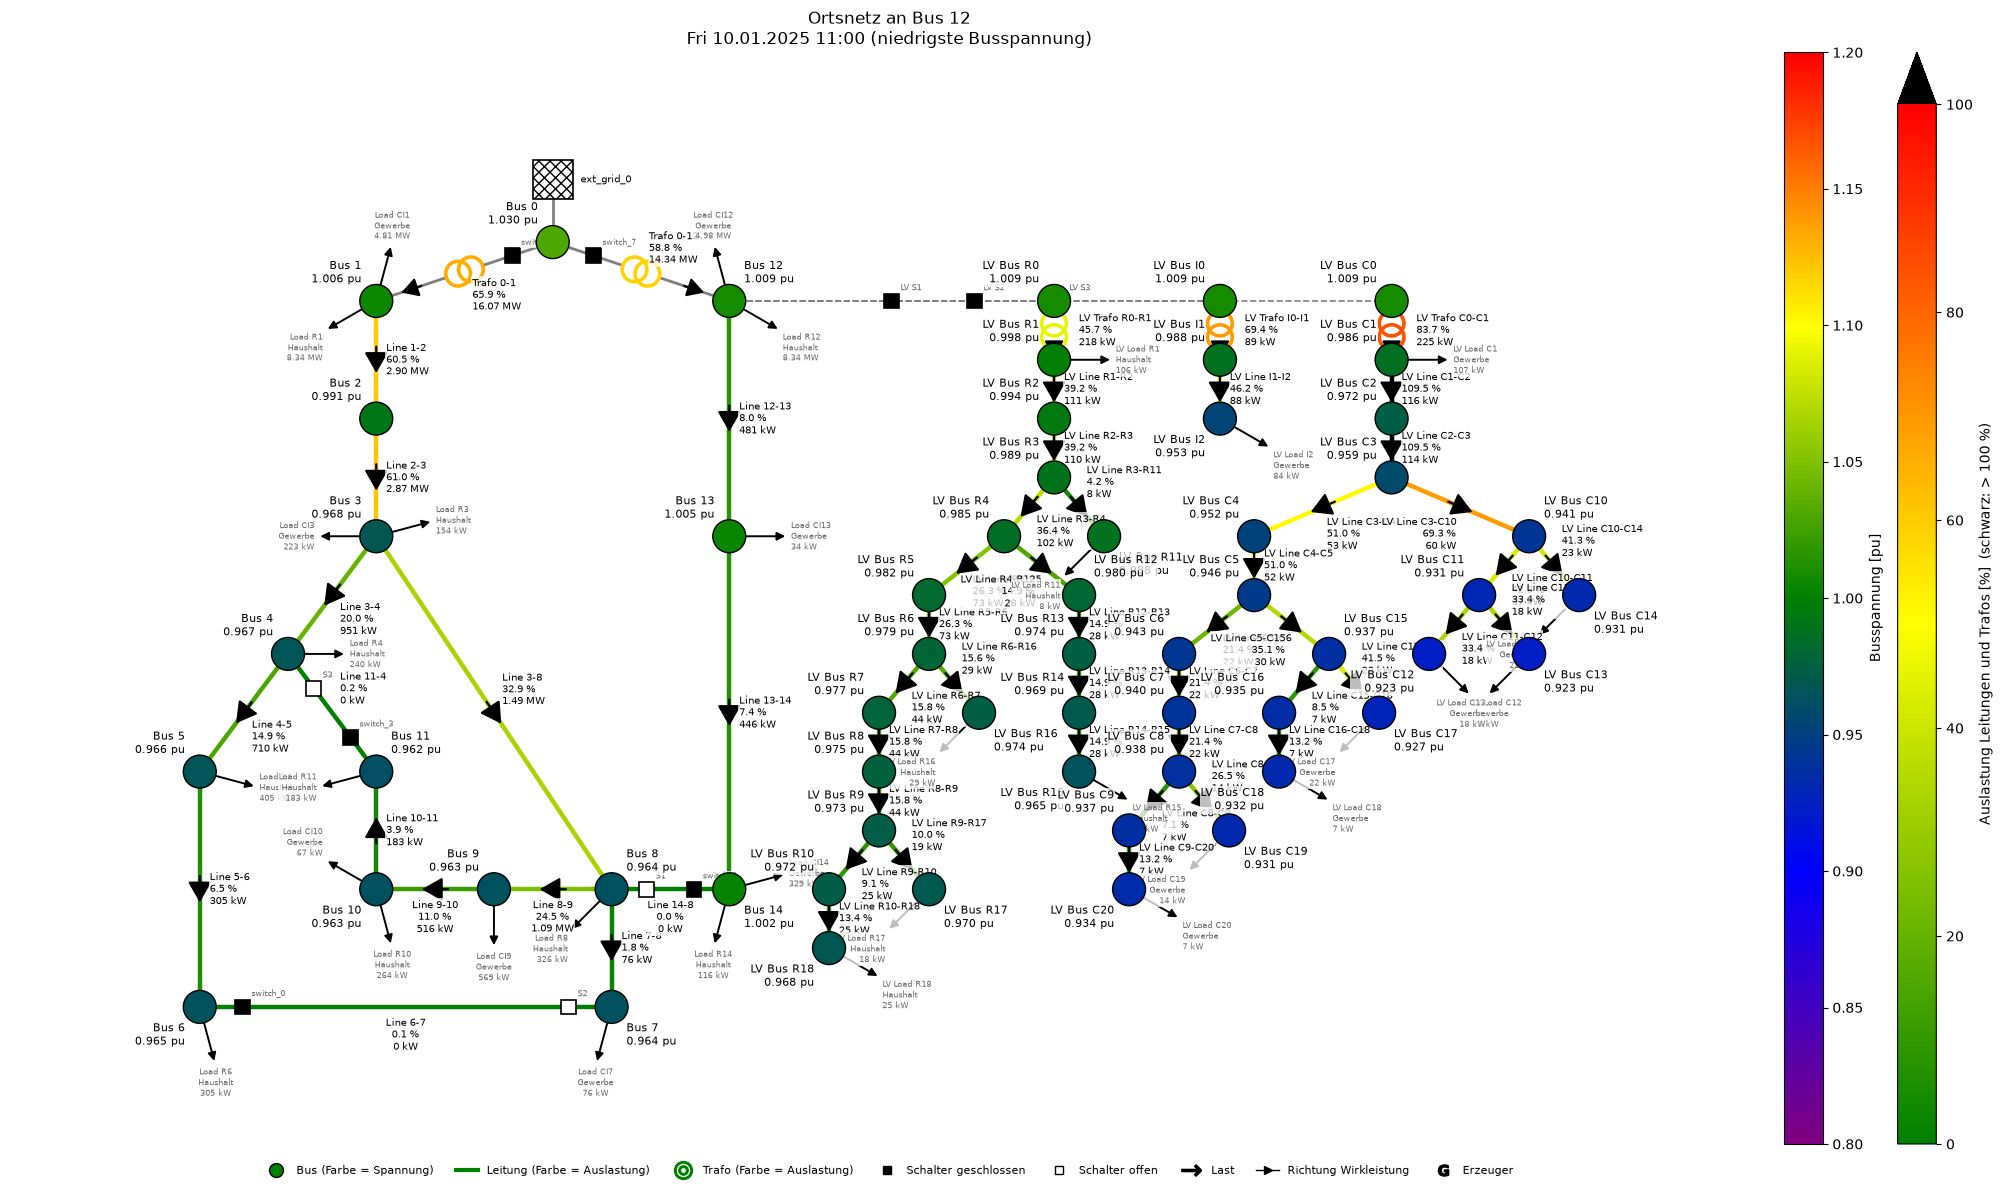

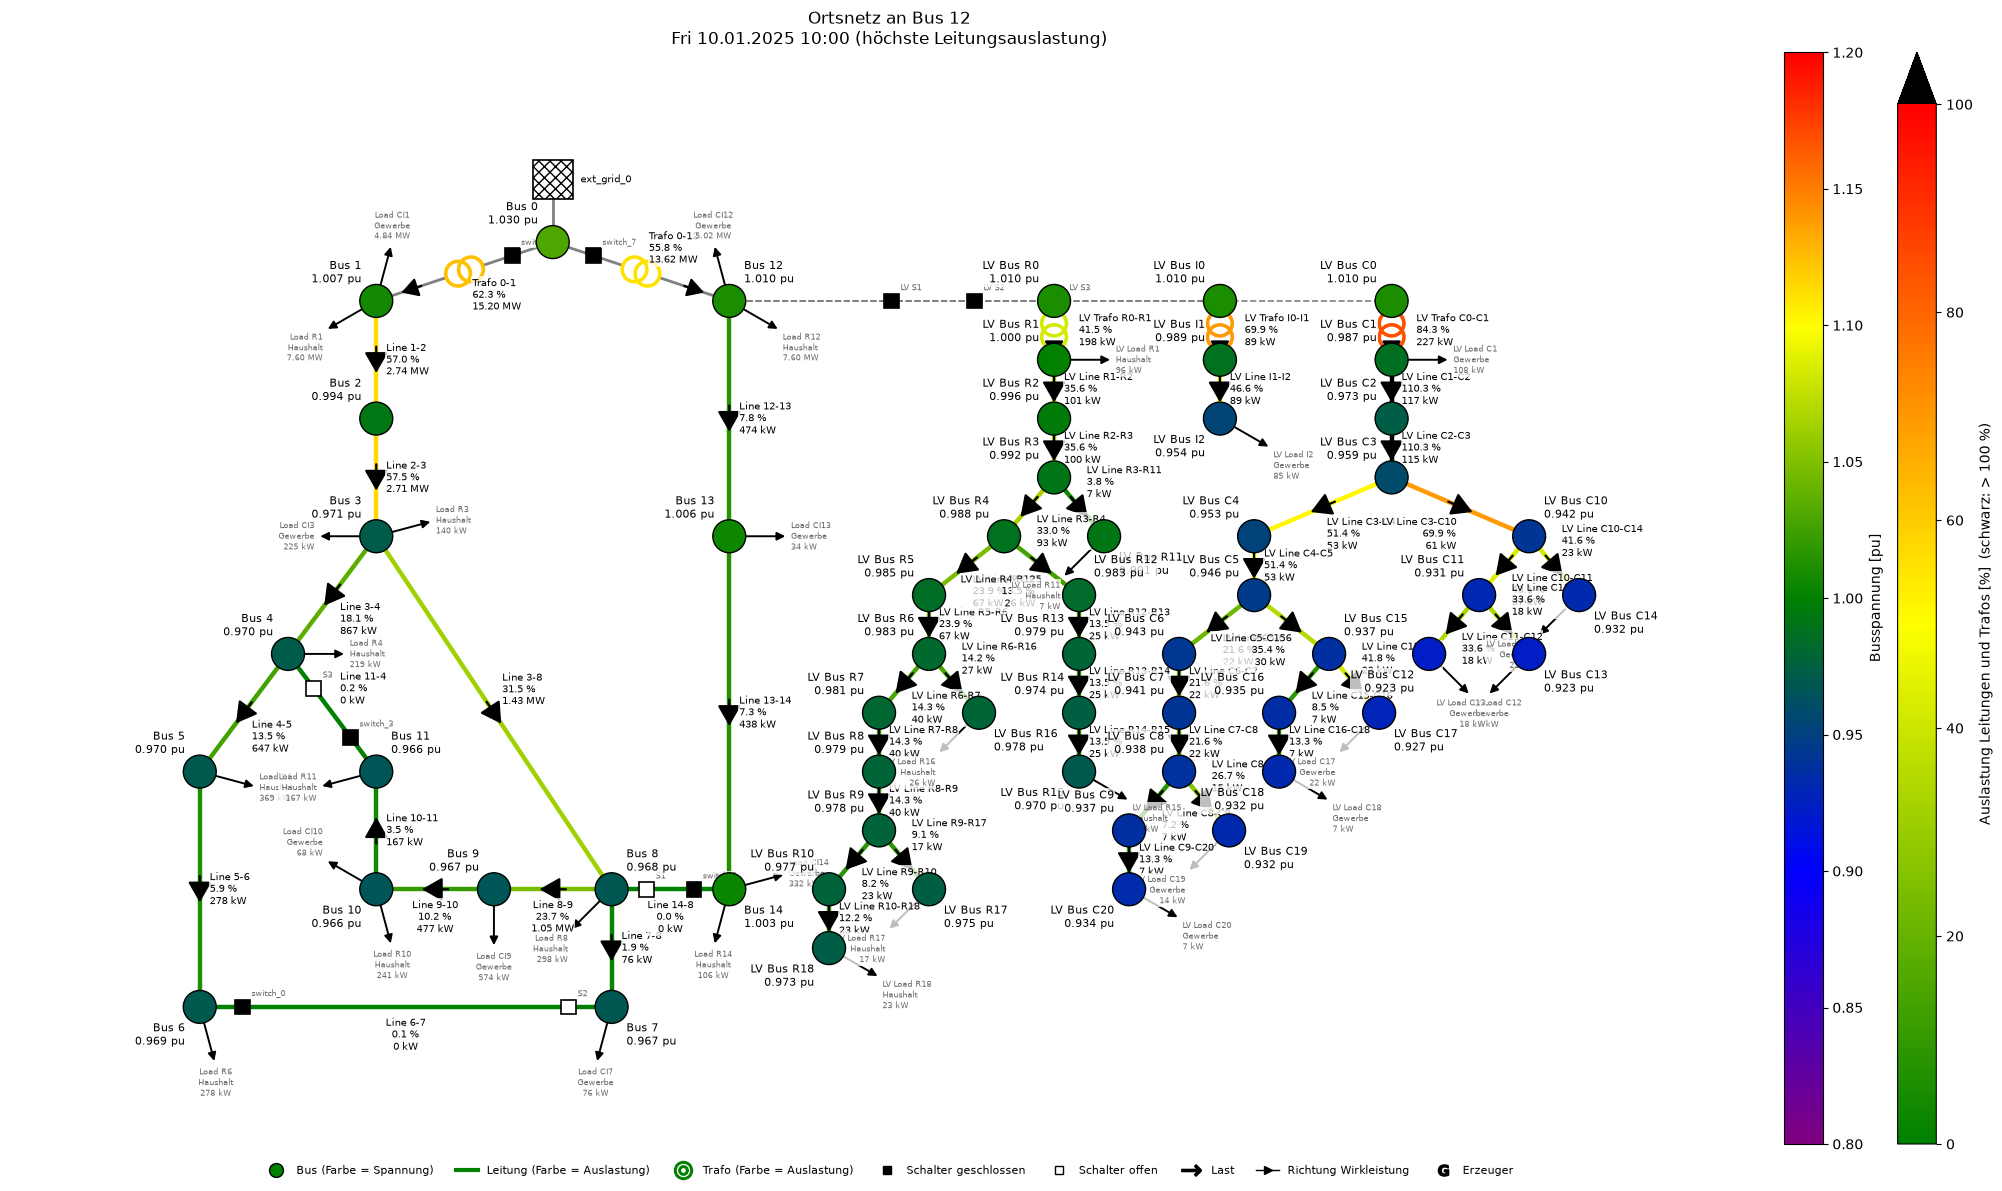

In [27]:
if gewaehlt:
    lv_sims[gewaehlt].createDiagram(Diagram.NETWORK, time=["min", "max_loading"], title=f"Ortsnetz an {gewaehlt}")

**Monatstabellen des gewählten Anschlussbusses** (niedrigste Spannung an allen Bussen, höchste Auslastung der Trafos):

In [28]:
if gewaehlt:
    display(plots.table(sz.monatstabelle(lv_sims[gewaehlt], "Spannung", "min"), decimals=3, cmap="RdYlGn", vmin=0.85, vmax=1.03))
    display(plots.table(sz.monatstabelle(lv_sims[gewaehlt], "Trafo", "max"), decimals=1, cmap="YlOrRd", vmin=0, vmax=100))

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Spannung min [pu],,,,,,,,,,,,
Bus 0,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030
Bus 1,1.002,1.002,1.006,1.008,1.011,1.012,1.012,1.013,1.011,1.008,1.004,1.002
Bus 2,0.984,0.984,0.990,0.993,0.999,1.000,1.000,1.001,0.998,0.993,0.986,0.984
Bus 3,0.955,0.956,0.964,0.970,0.980,0.981,0.981,0.983,0.978,0.969,0.959,0.956
Bus 4,0.953,0.954,0.963,0.968,0.978,0.979,0.980,0.981,0.976,0.968,0.957,0.954
Bus 5,0.952,0.953,0.962,0.967,0.978,0.979,0.979,0.981,0.975,0.967,0.956,0.953
Bus 6,0.950,0.952,0.961,0.966,0.977,0.978,0.978,0.980,0.974,0.966,0.955,0.951
Bus 7,0.950,0.952,0.961,0.966,0.977,0.978,0.979,0.980,0.975,0.966,0.955,0.951
Bus 8,0.951,0.952,0.961,0.966,0.977,0.978,0.979,0.980,0.975,0.966,0.955,0.952


month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Trafo max [%],,,,,,,,,,,,
Trafo 0-1,82.7,81.8,73.6,69.2,59.1,57.8,57.2,56.0,61.2,68.7,79.2,81.4
Trafo 0-12,70.7,69.6,63.1,59.1,50.7,49.8,49.1,48.1,52.4,59.0,67.4,70.0
LV Trafo R0-R1,84.0,82.8,72.6,69.4,58.2,55.8,56.4,55.0,60.9,69.0,79.7,80.2
LV Trafo I0-I1,69.9,69.0,67.1,61.8,58.4,57.2,53.0,54.5,57.2,59.8,68.8,66.1
LV Trafo C0-C1,84.3,83.3,81.0,74.6,70.4,69.0,64.0,65.8,69.1,72.2,83.1,79.8


## 7 Ergebnis

**Gewählt wird Bus 12** als Anschlussbus des Ortsnetzes.

| Kennwert | Bus 12 | Bus 1 | Bus 13 | Bus 14 |
|---|---|---|---|---|
| niedrigste Spannung (MV und LV) | **0,923 pu** | 0,918 pu | 0,913 pu | 0,908 pu |
| höchste Auslastung MV-Leitungen | **78,6 %** | 78,7 % | 78,6 % | 78,6 % |
| höchste Auslastung LV-Leitungen | **110,3 %** | 110,8 % | 111,4 % | 112,1 % |
| höchste Auslastung Trafos 110/20 kV | **82,7 %** | 84,9 % | 82,7 % | 82,7 % |
| höchste Auslastung Ortsnetztrafos | **84,3 %** | 84,7 % | 85,1 % | 85,6 % |

Bus 12 ist bei allen fünf Kriterien der beste (oder gleich gute) Anschlussbus:

- **Spannung:** Bus 12 ist die 20-kV-Sammelschiene von Trafo 0-12. Sie wird ohne Leitung direkt vom Trafo versorgt, und Abgang 2 ist nur schwach belastet. Die MV-Spannung bleibt dort das ganze Jahr über 1,00 pu, deshalb bleibt für das Ortsnetz die größte Reserve bis 0,90 pu. Bus 13 und Bus 14 liegen hinter den Freileitungen und haben einen zusätzlichen Spannungsfall.
- **MV-Auslastung:** Das Ortsnetz belastet nur Trafo 0-12 (68,4 % → 70,7 %), der die größte Reserve hat. Line 1-2, Line 2-3 und Trafo 0-1 in Abgang 1 bleiben unverändert. Bei Bus 1 würde dagegen der ohnehin höher belastete Trafo 0-1 von 82,7 % auf 84,9 % steigen.
- **LV-Auslastung:** Durch die höhere Spannung fließt für dieselbe Leistung weniger Strom. Deshalb ist auch die Überlastung von Line C1-C2 bei Bus 12 am geringsten (110,3 %, 65 Stunden).

Mit Bus 12 muss im Normalbetrieb am wenigsten geregelt werden, und der vorbelastete Abgang 1 wird nicht zusätzlich belastet. Die Überlastung von Line C1-C2 im Ortsnetz selbst bleibt als offener Befund für die weiteren Teilaufgaben bestehen.

## 8 Anhang: Netzpläne aller Anschlussvarianten

Für jeden Anschlussbus der Netzplan zum Zeitpunkt der höchsten Leitungsauslastung über alle 12 Wochen. Das LV-Netz ist rechts neben dem MV-Netz dargestellt; die gestrichelten grauen Linien verbinden den Anschlussbus mit den 20-kV-Seiten der drei Ortsnetztrafos (Schalter LV S1–S3).

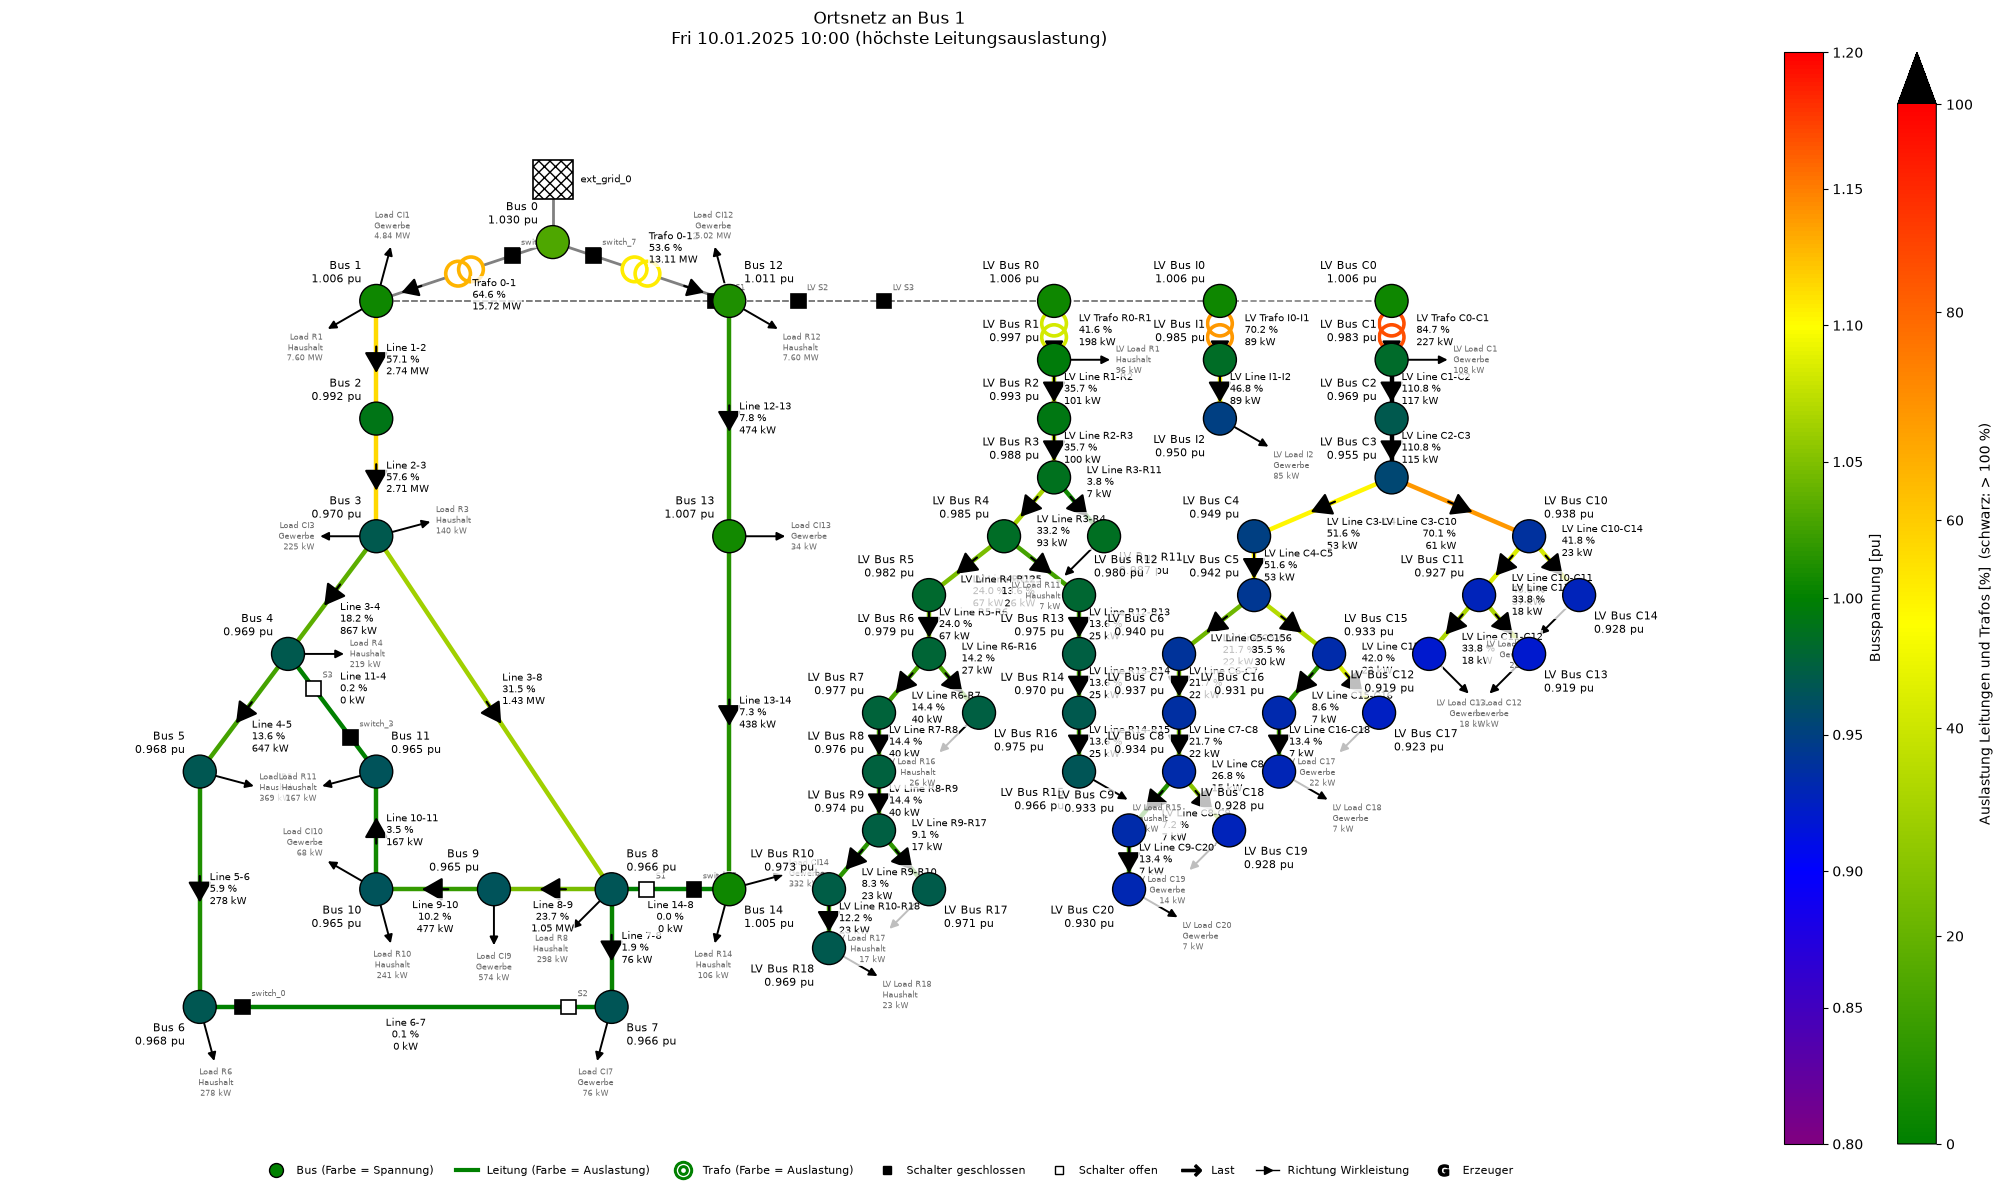

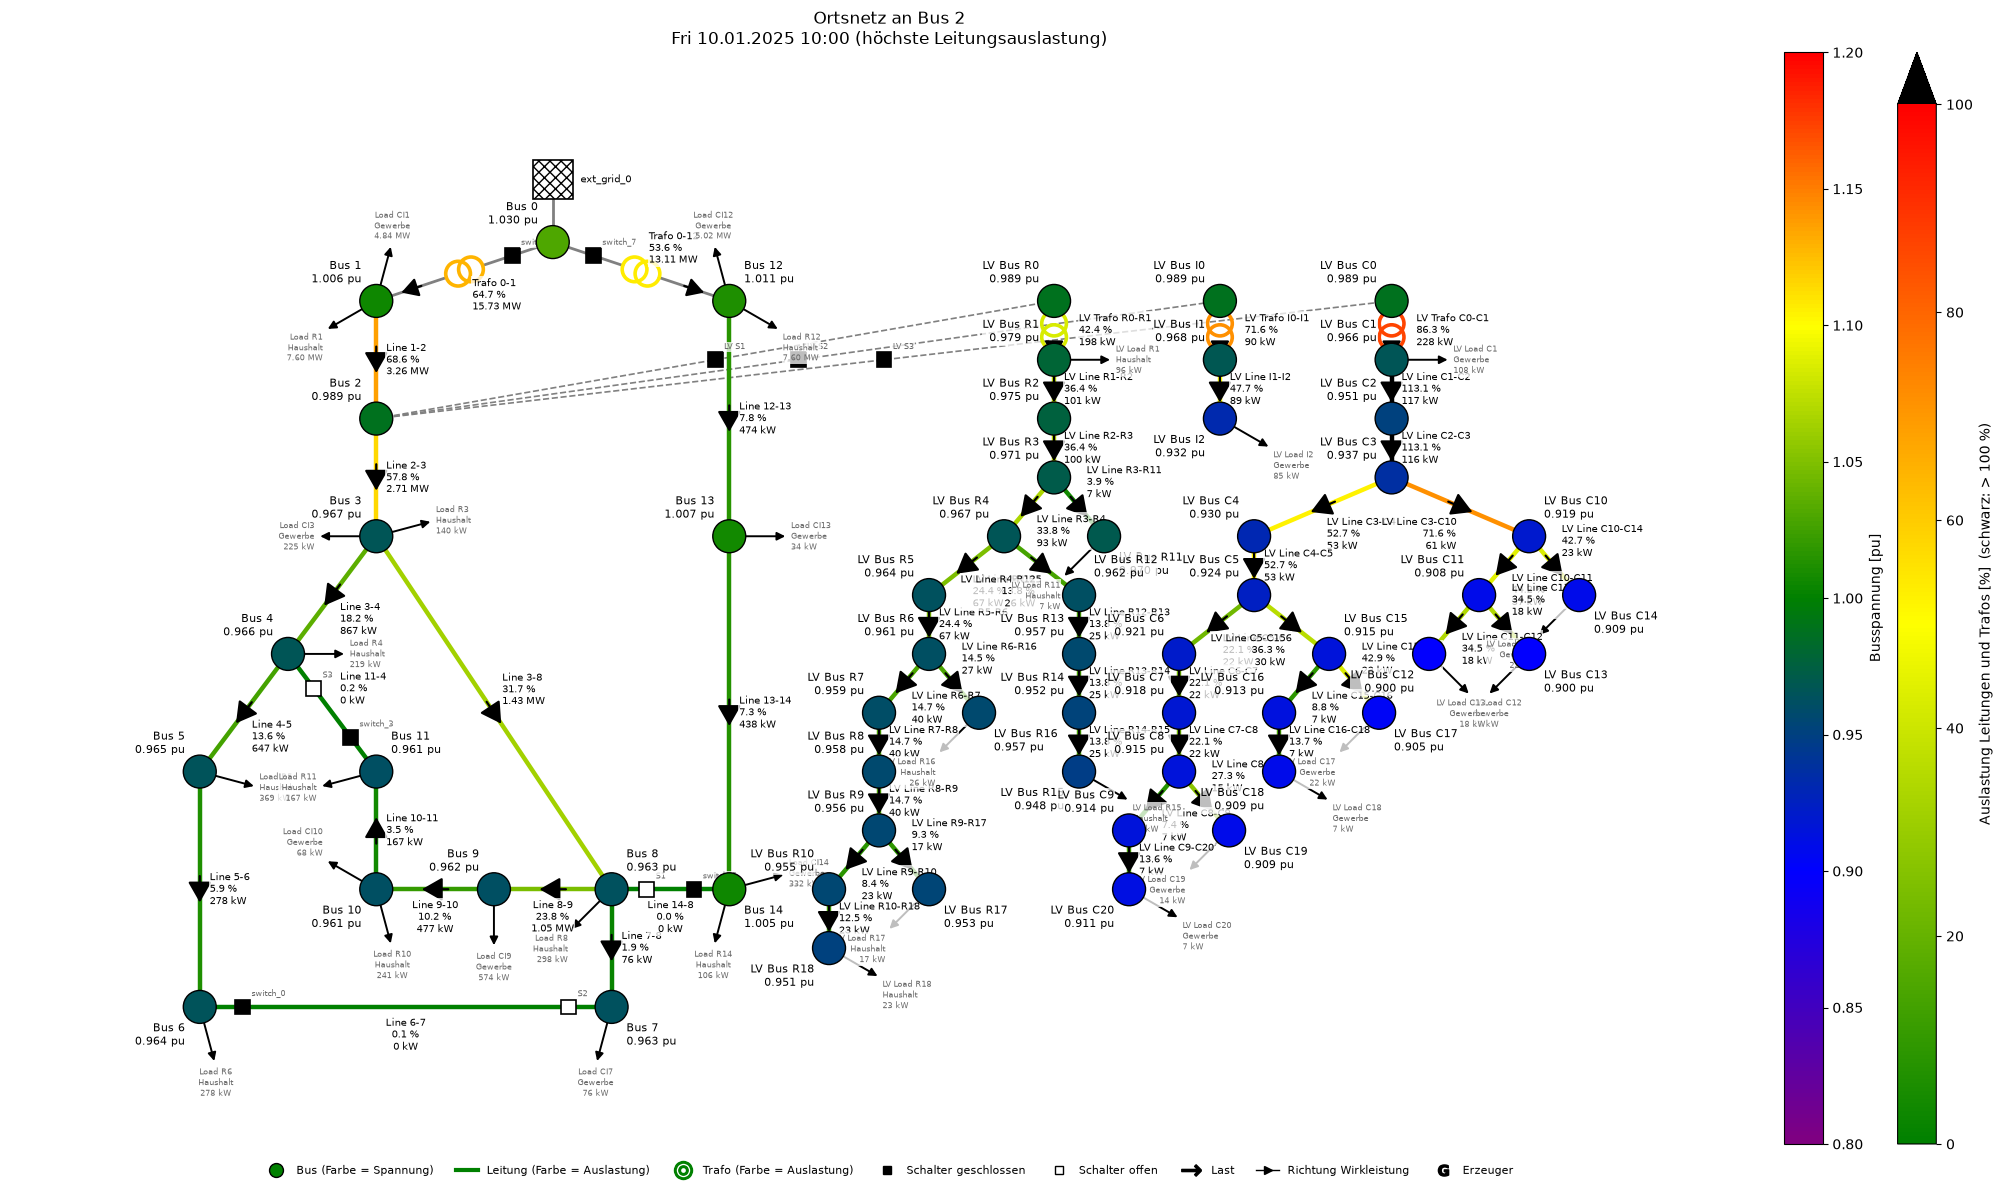

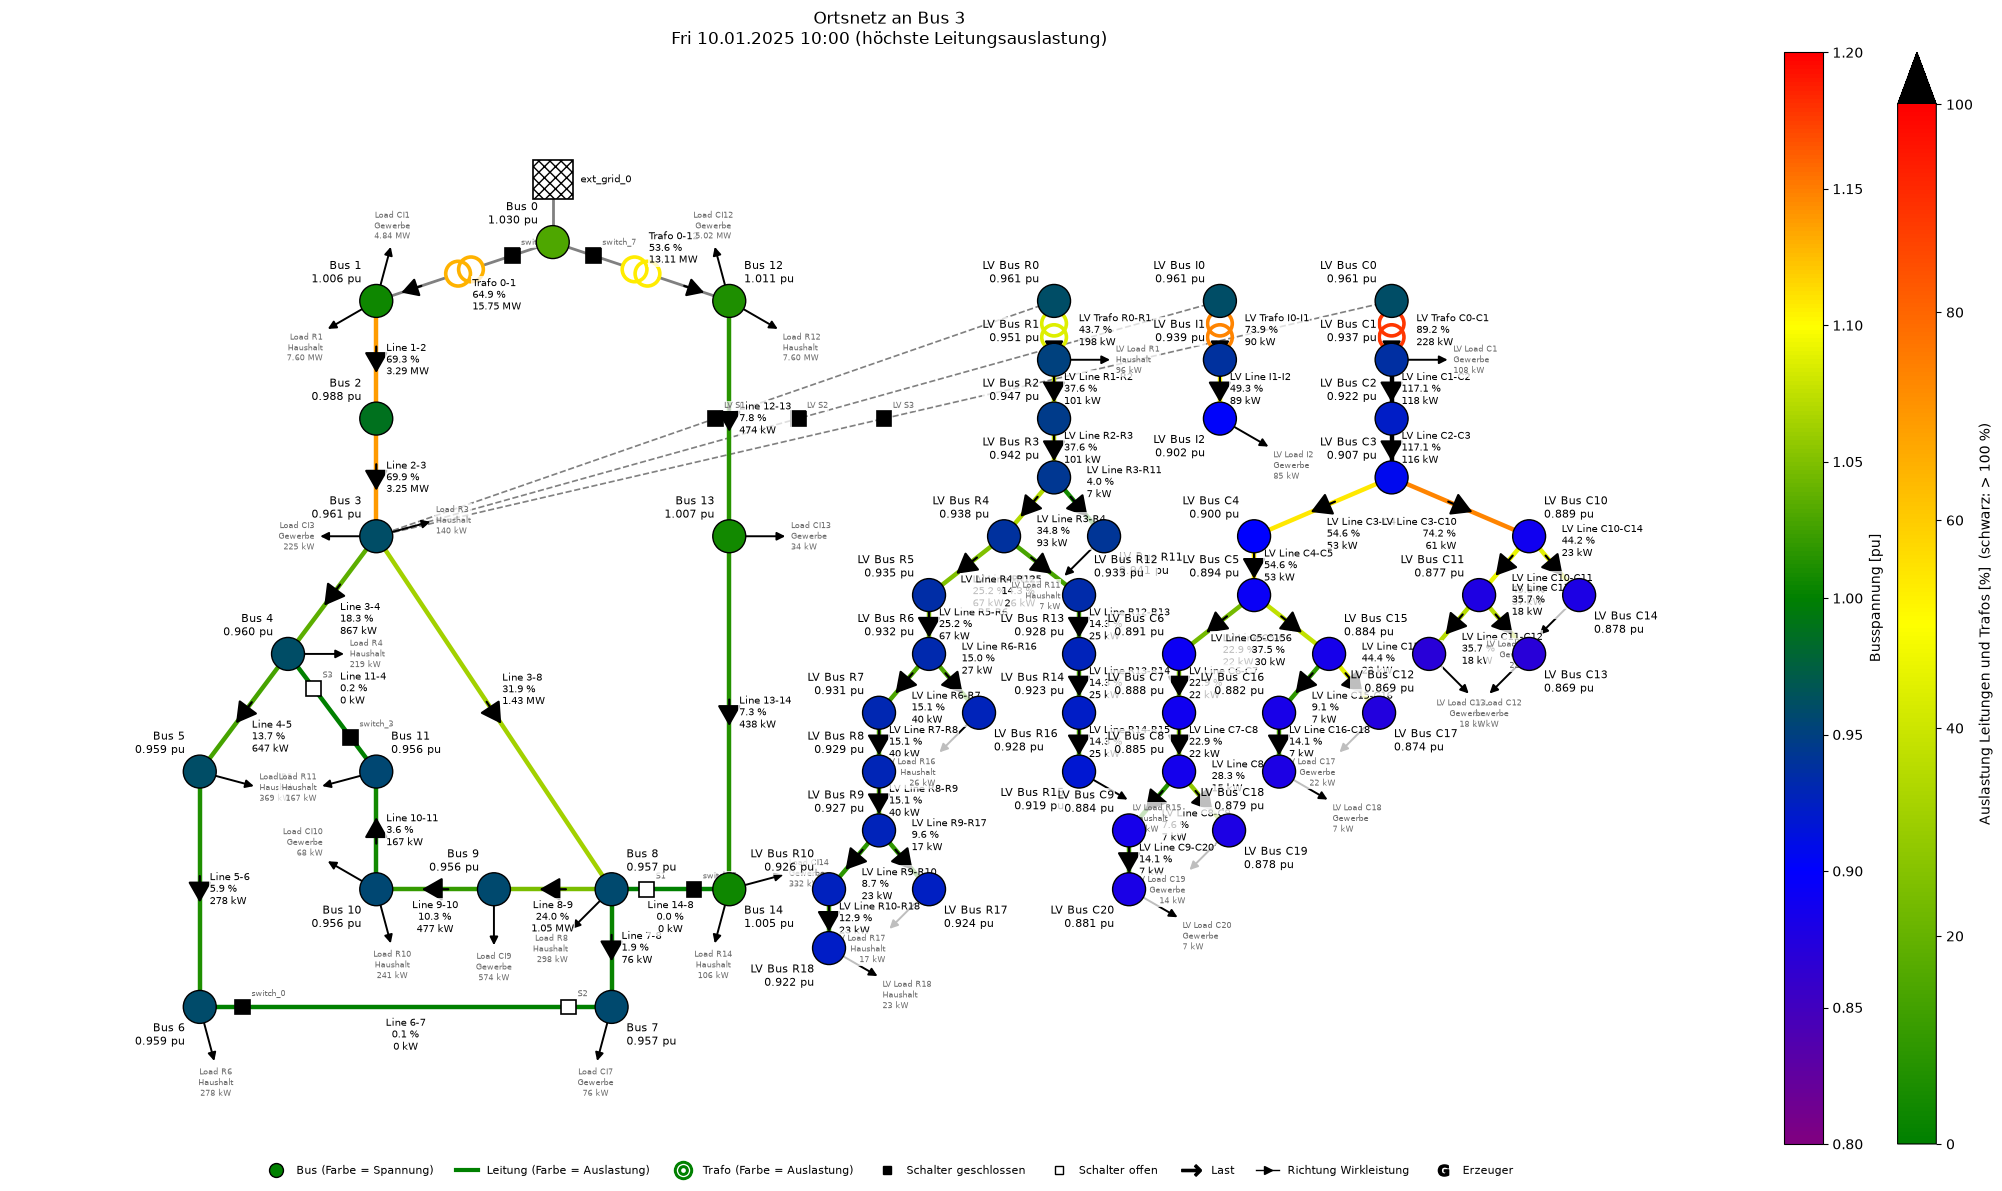

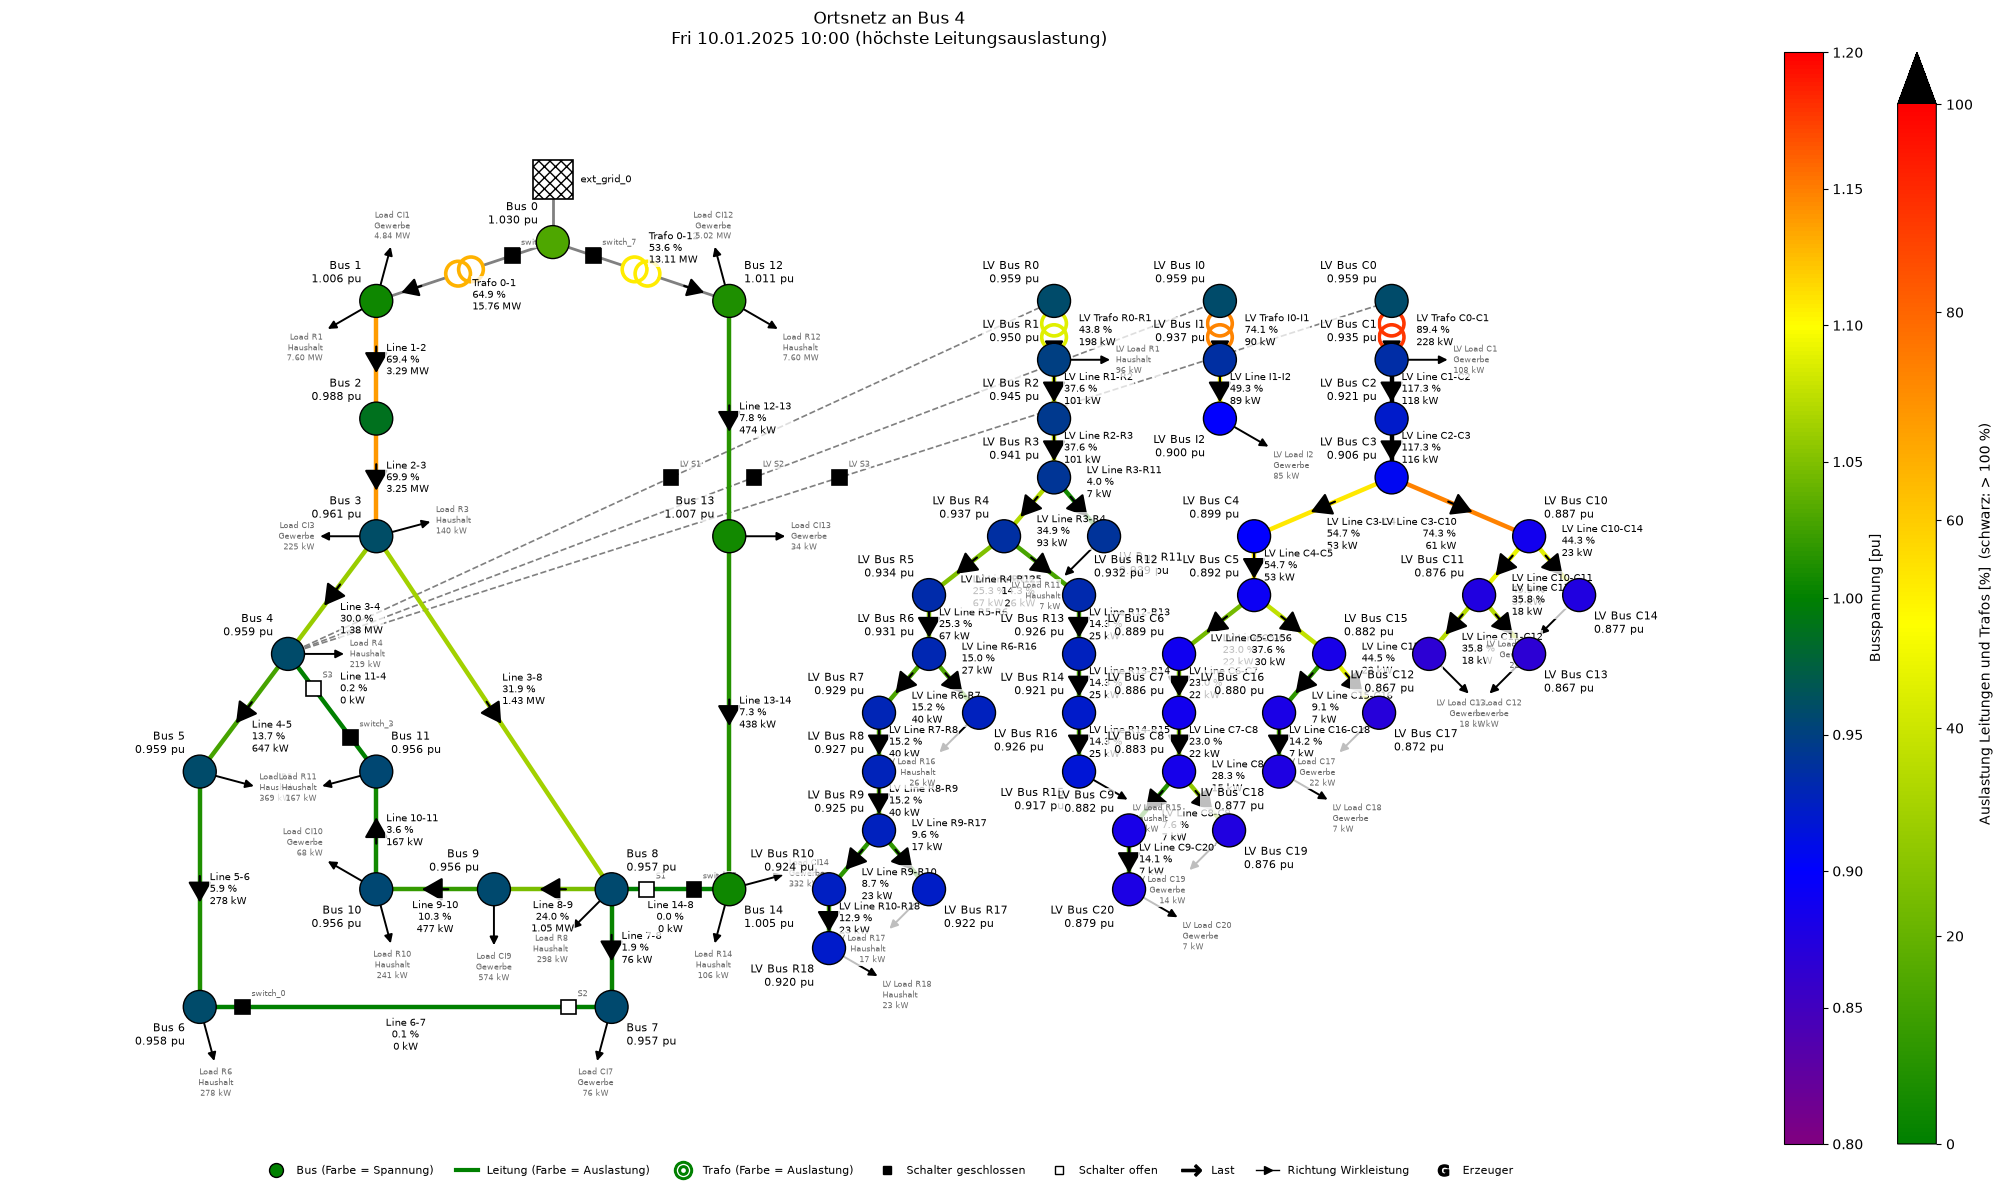

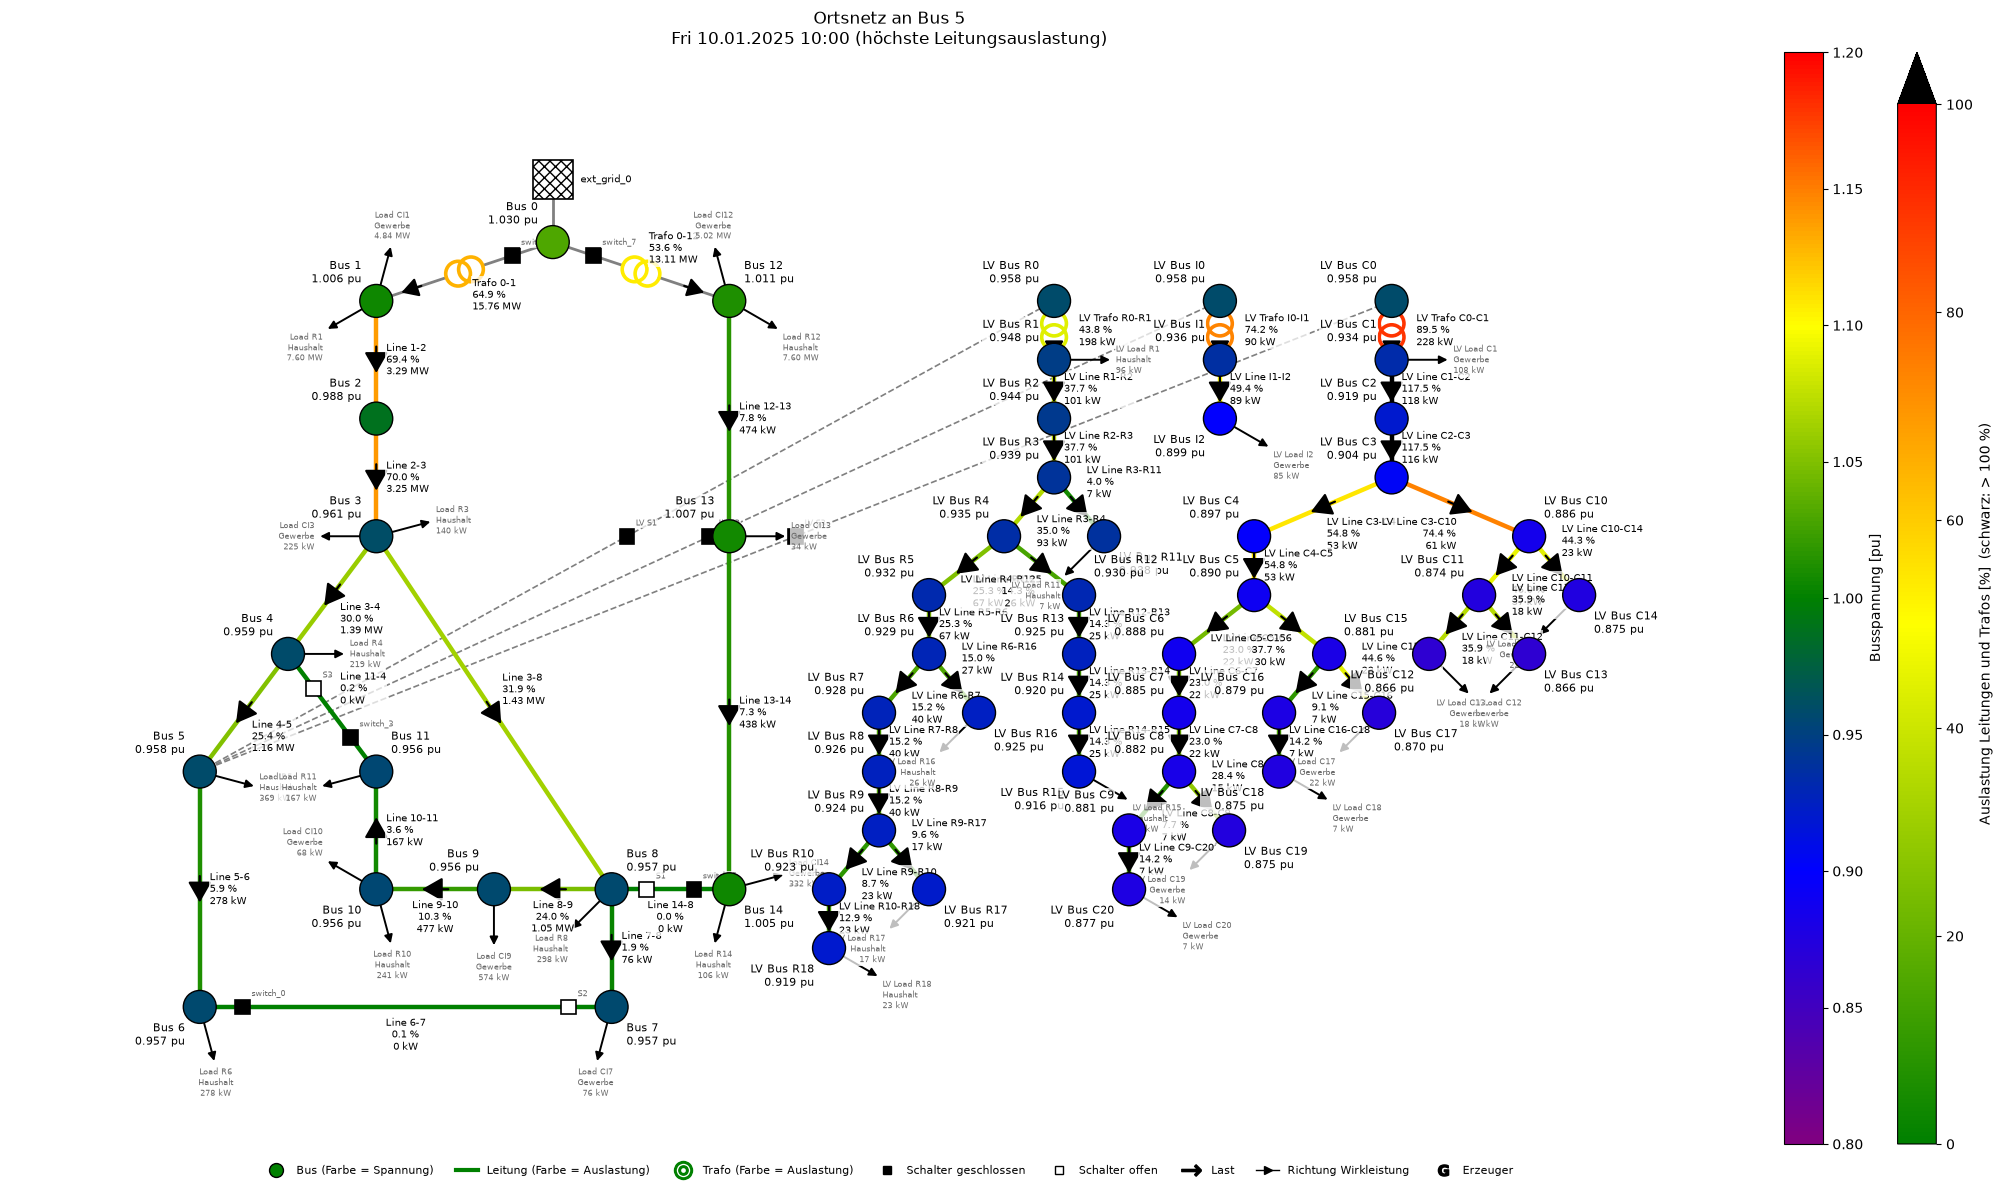

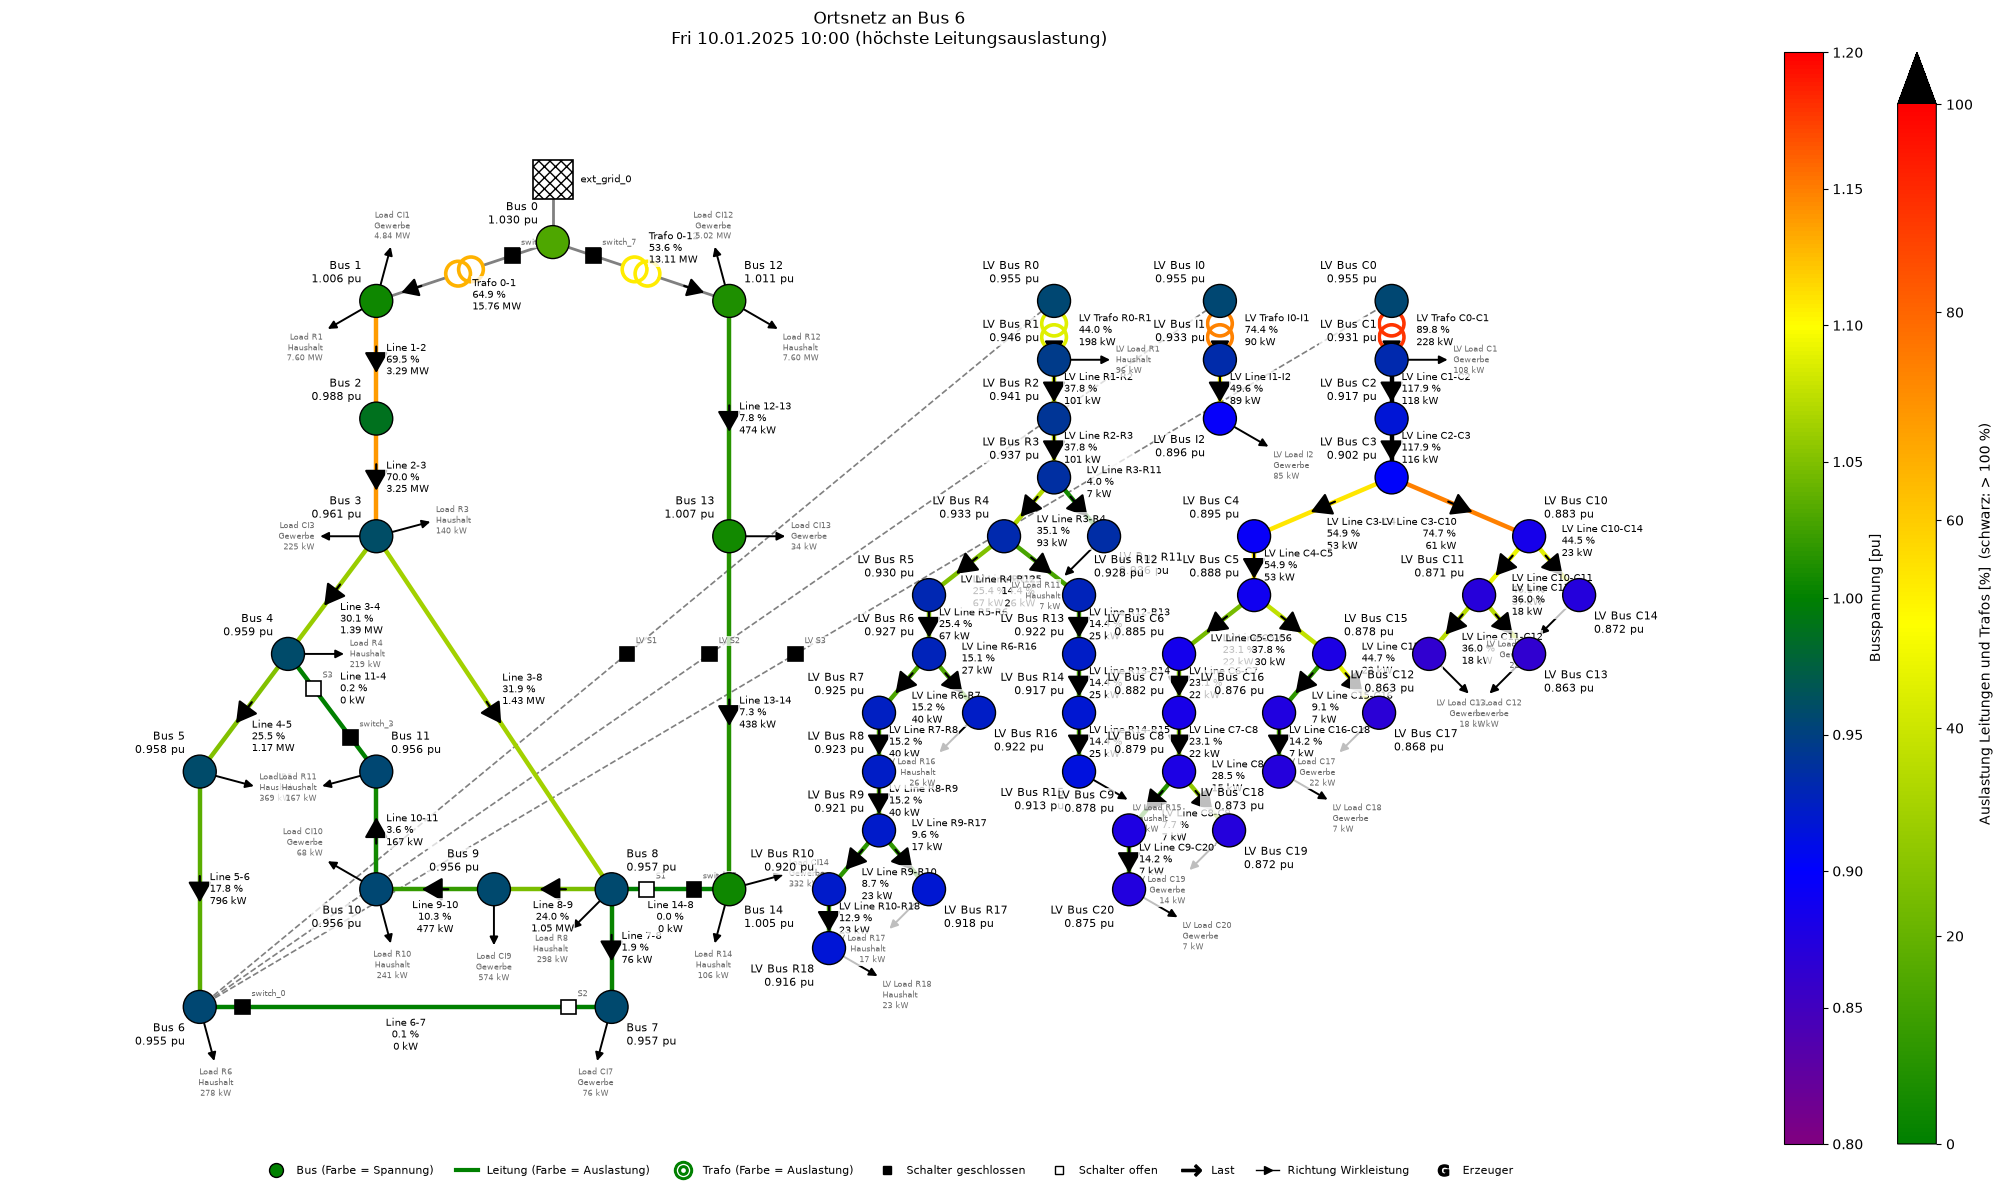

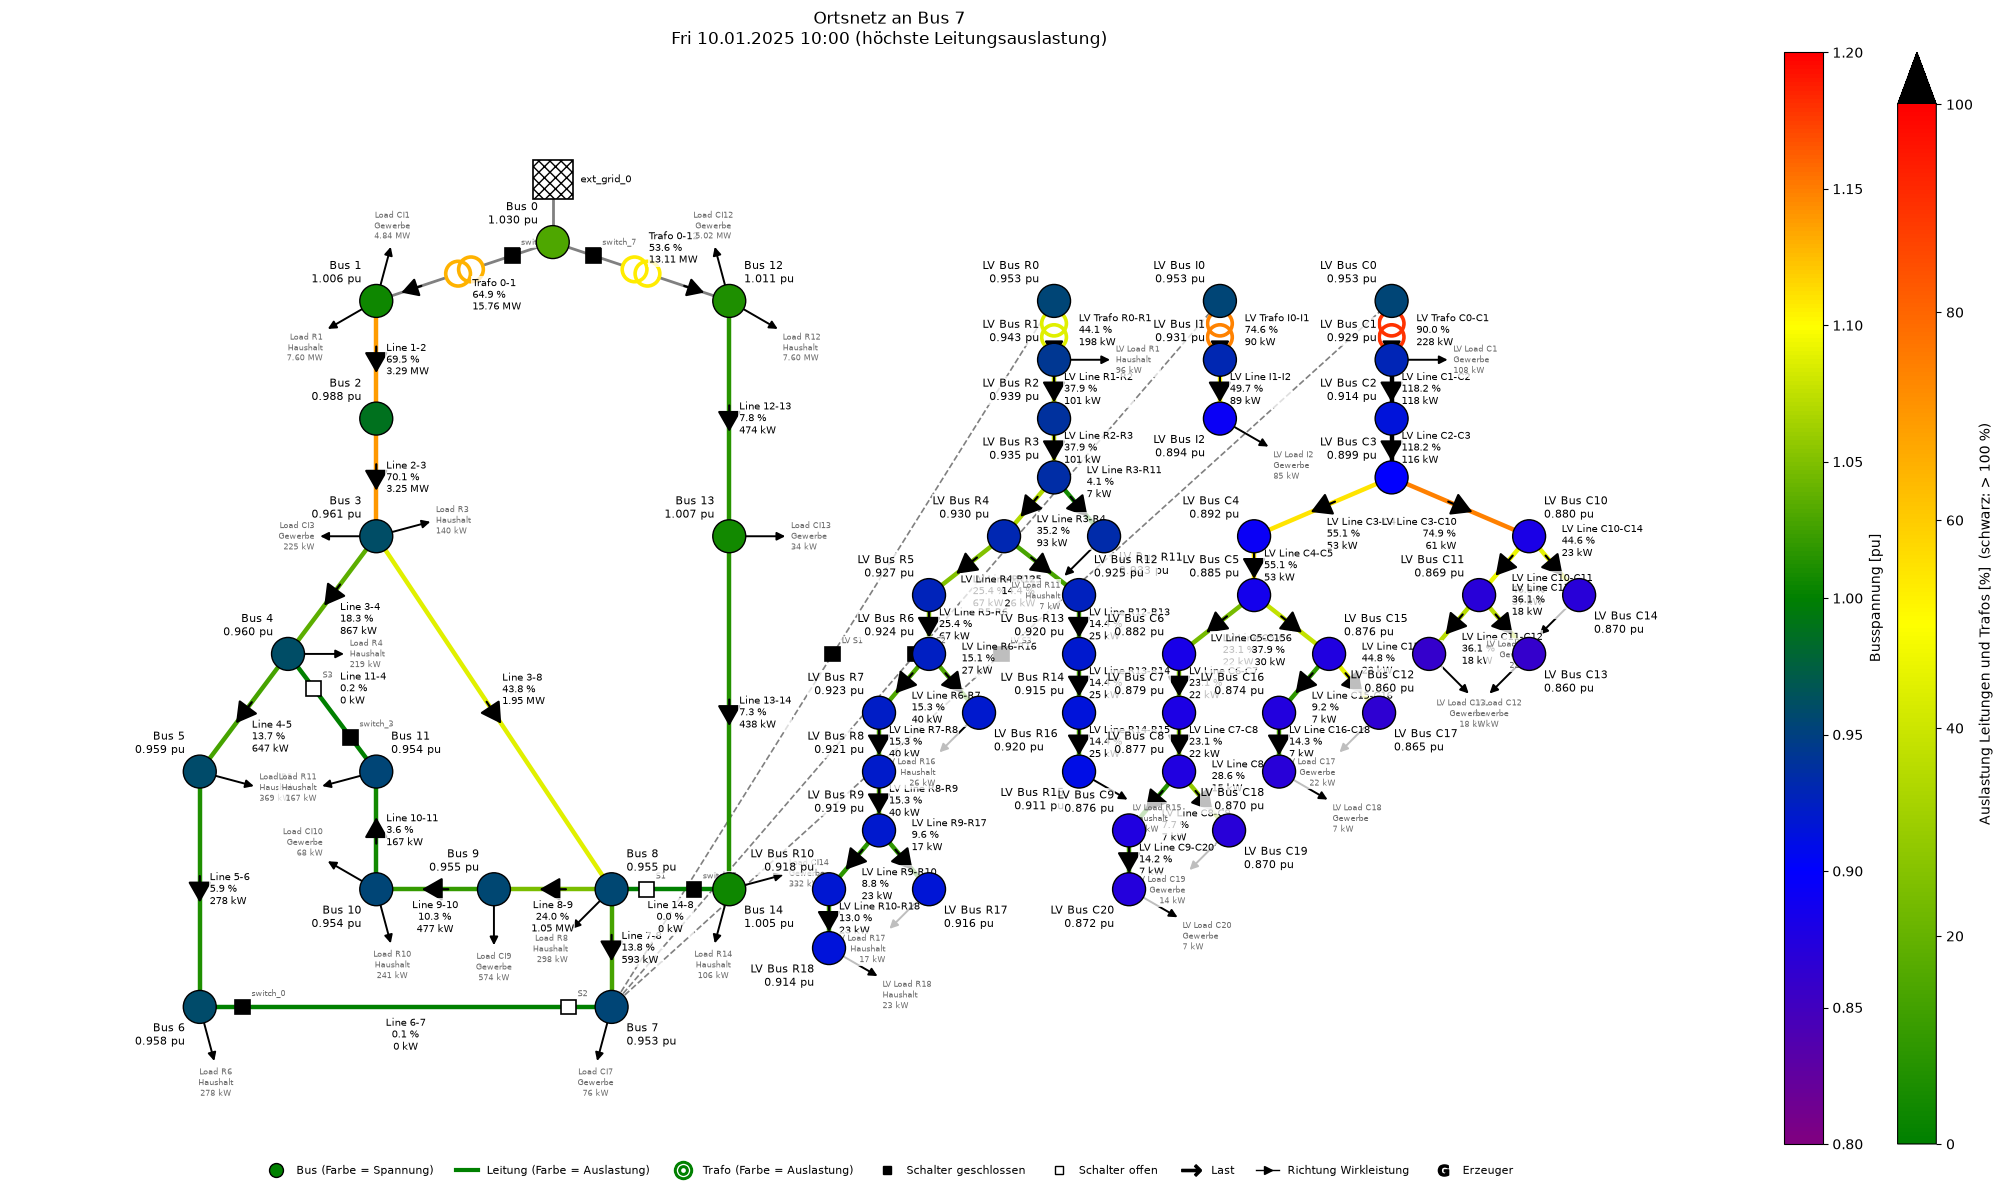

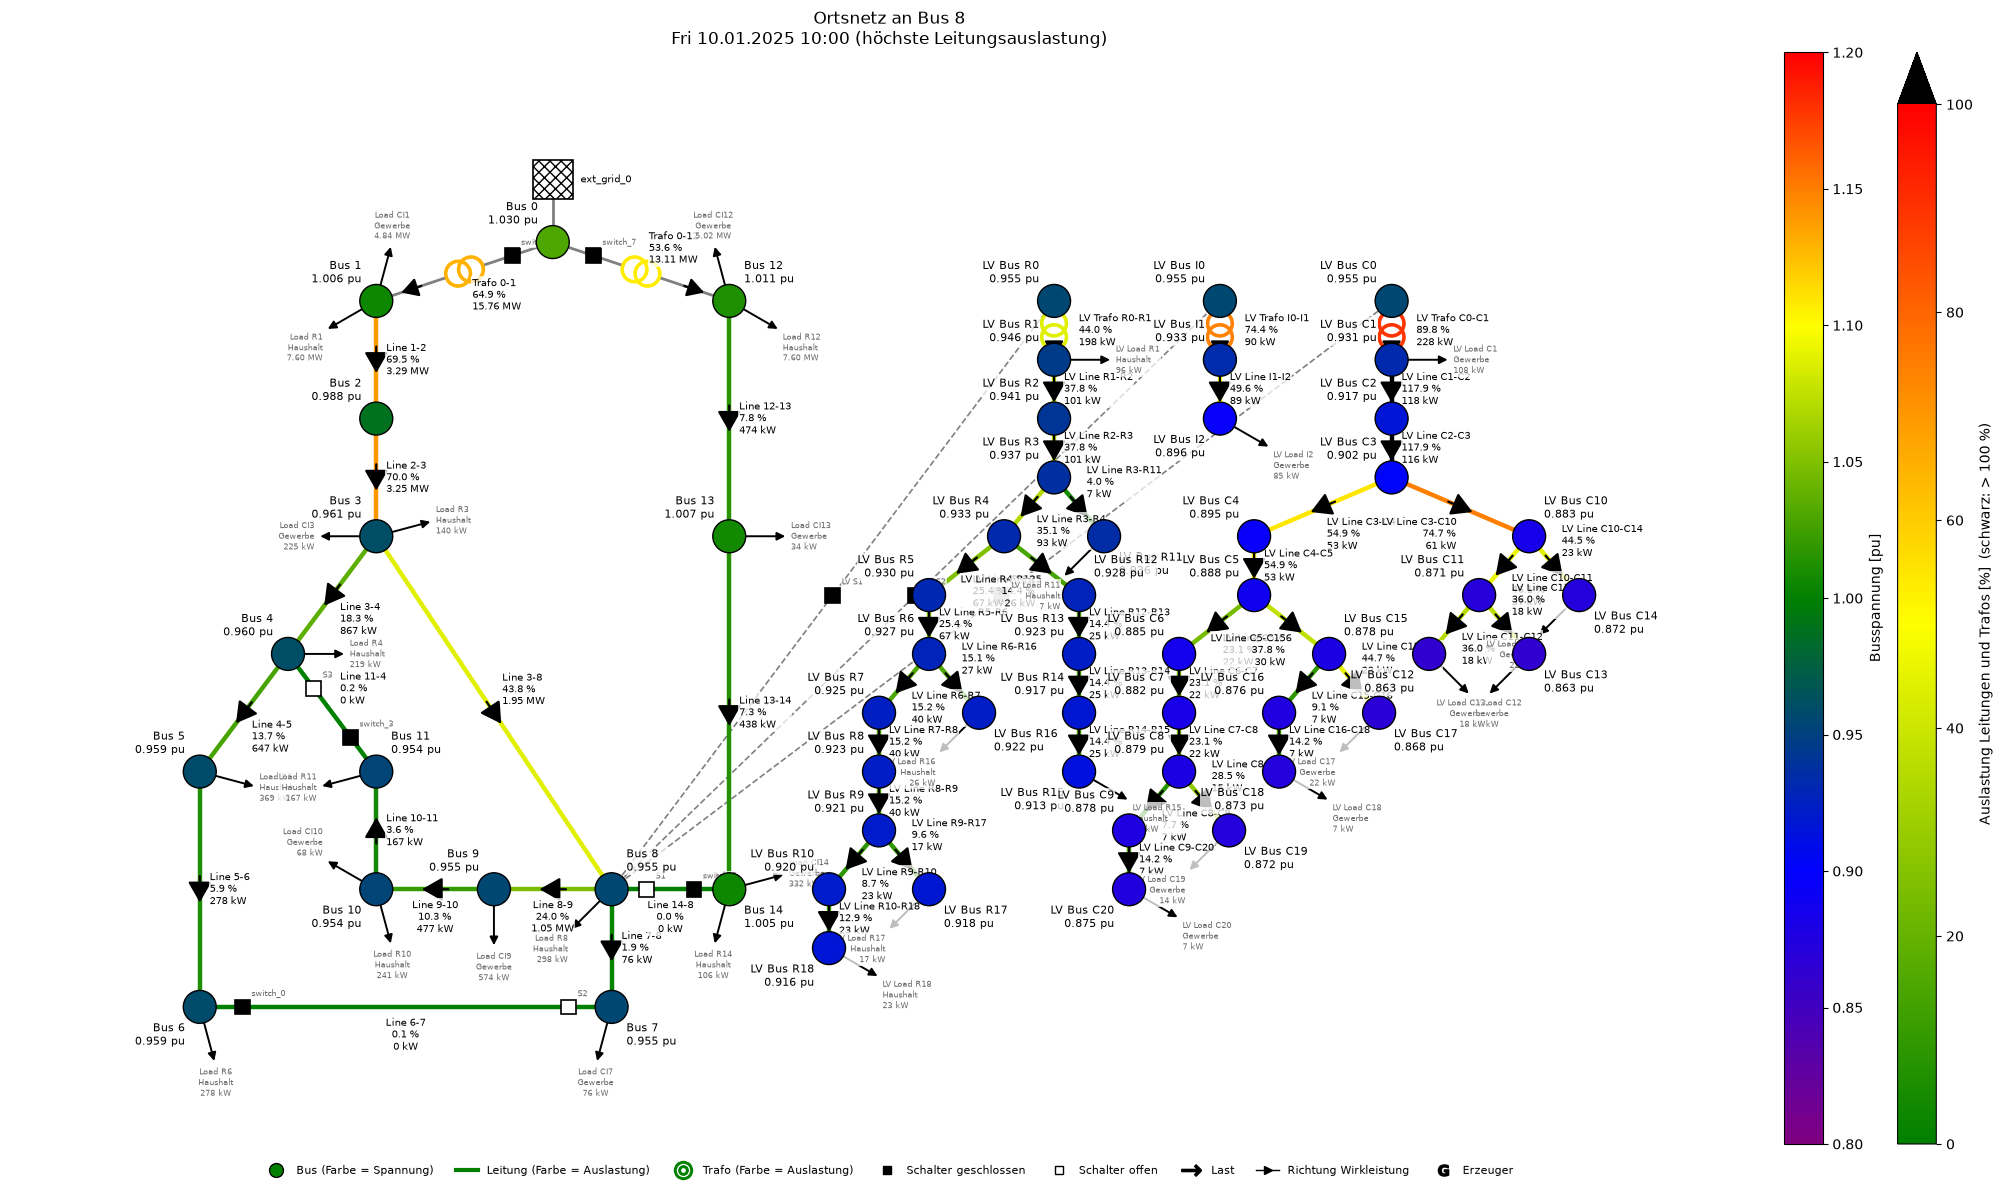

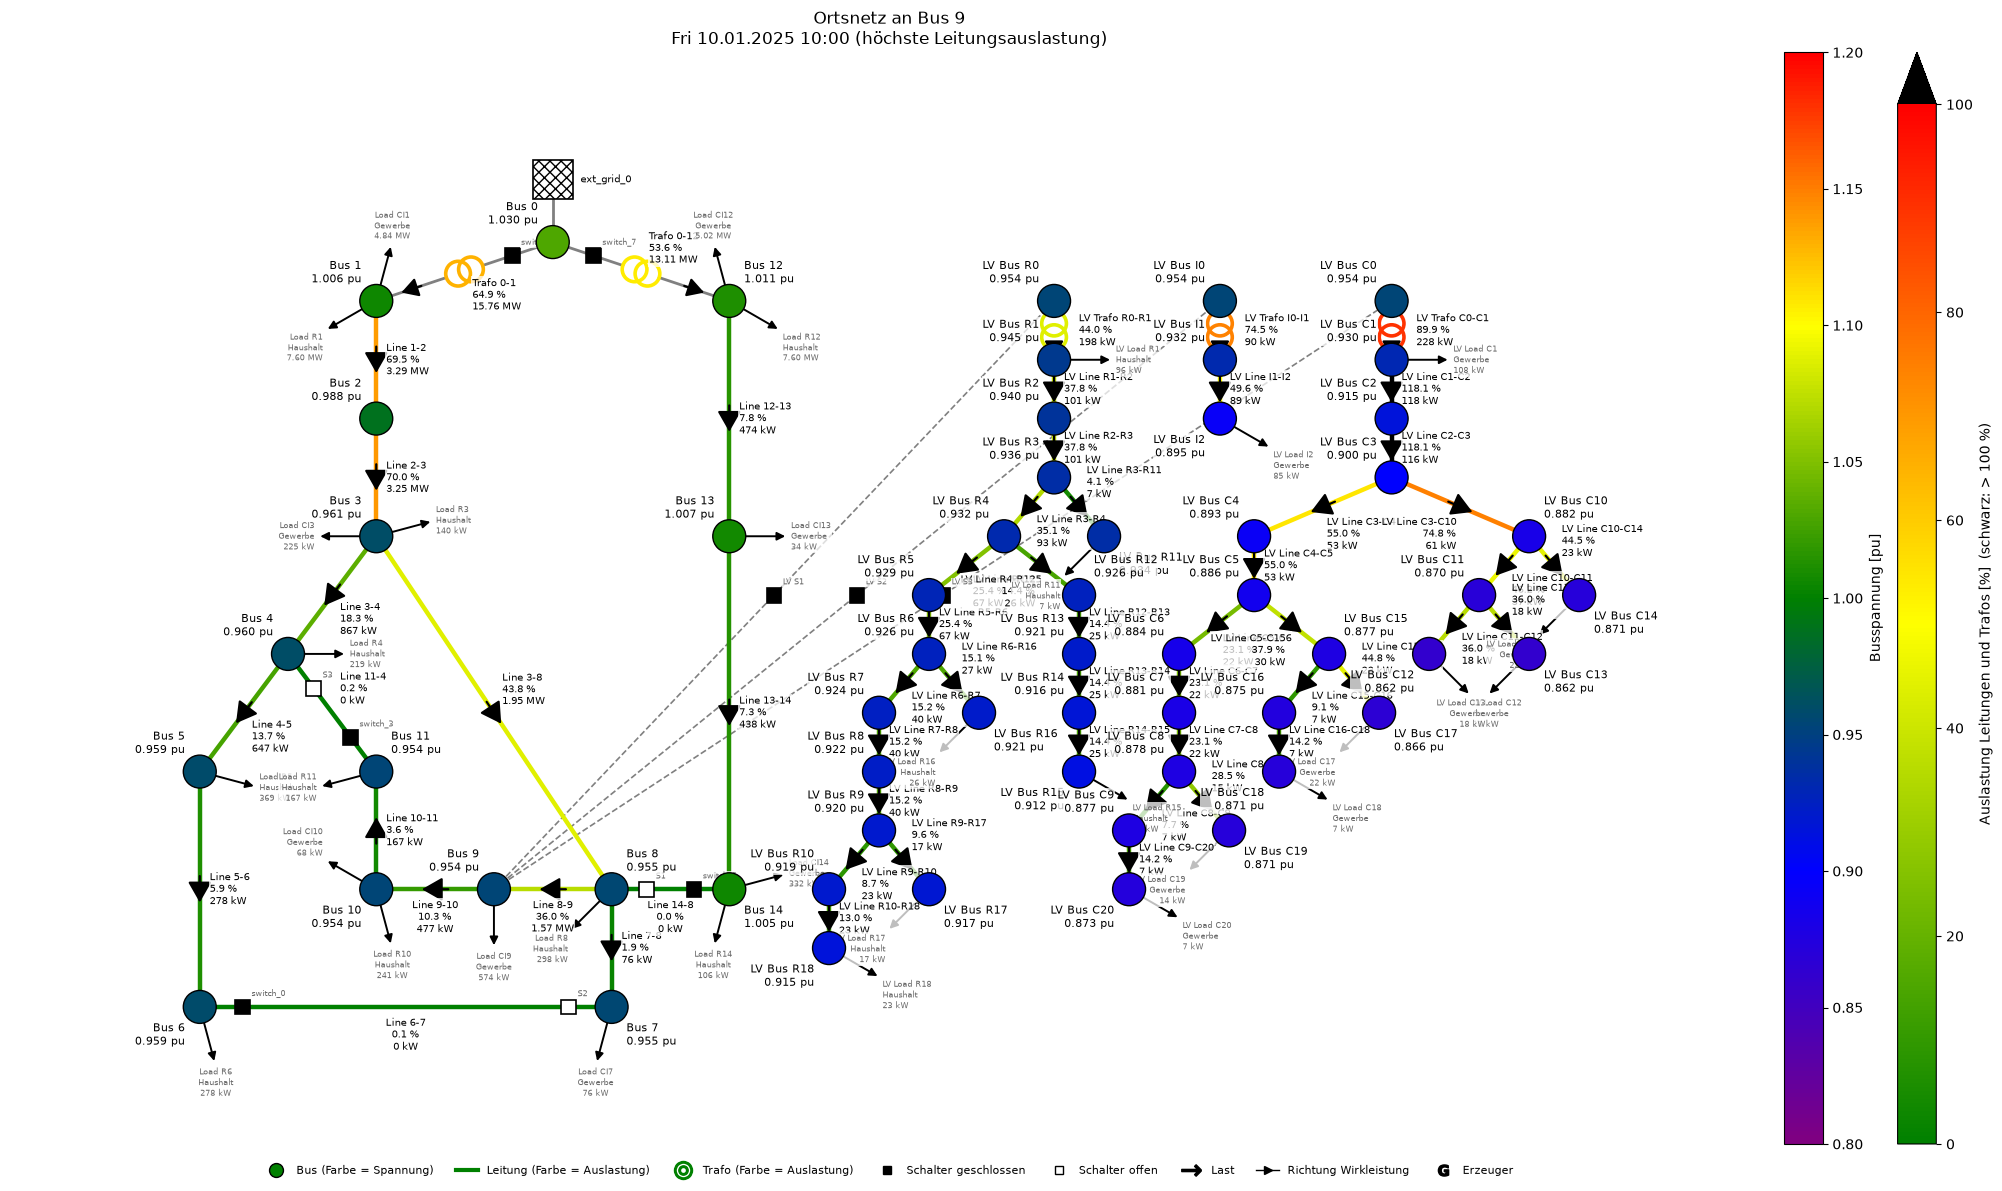

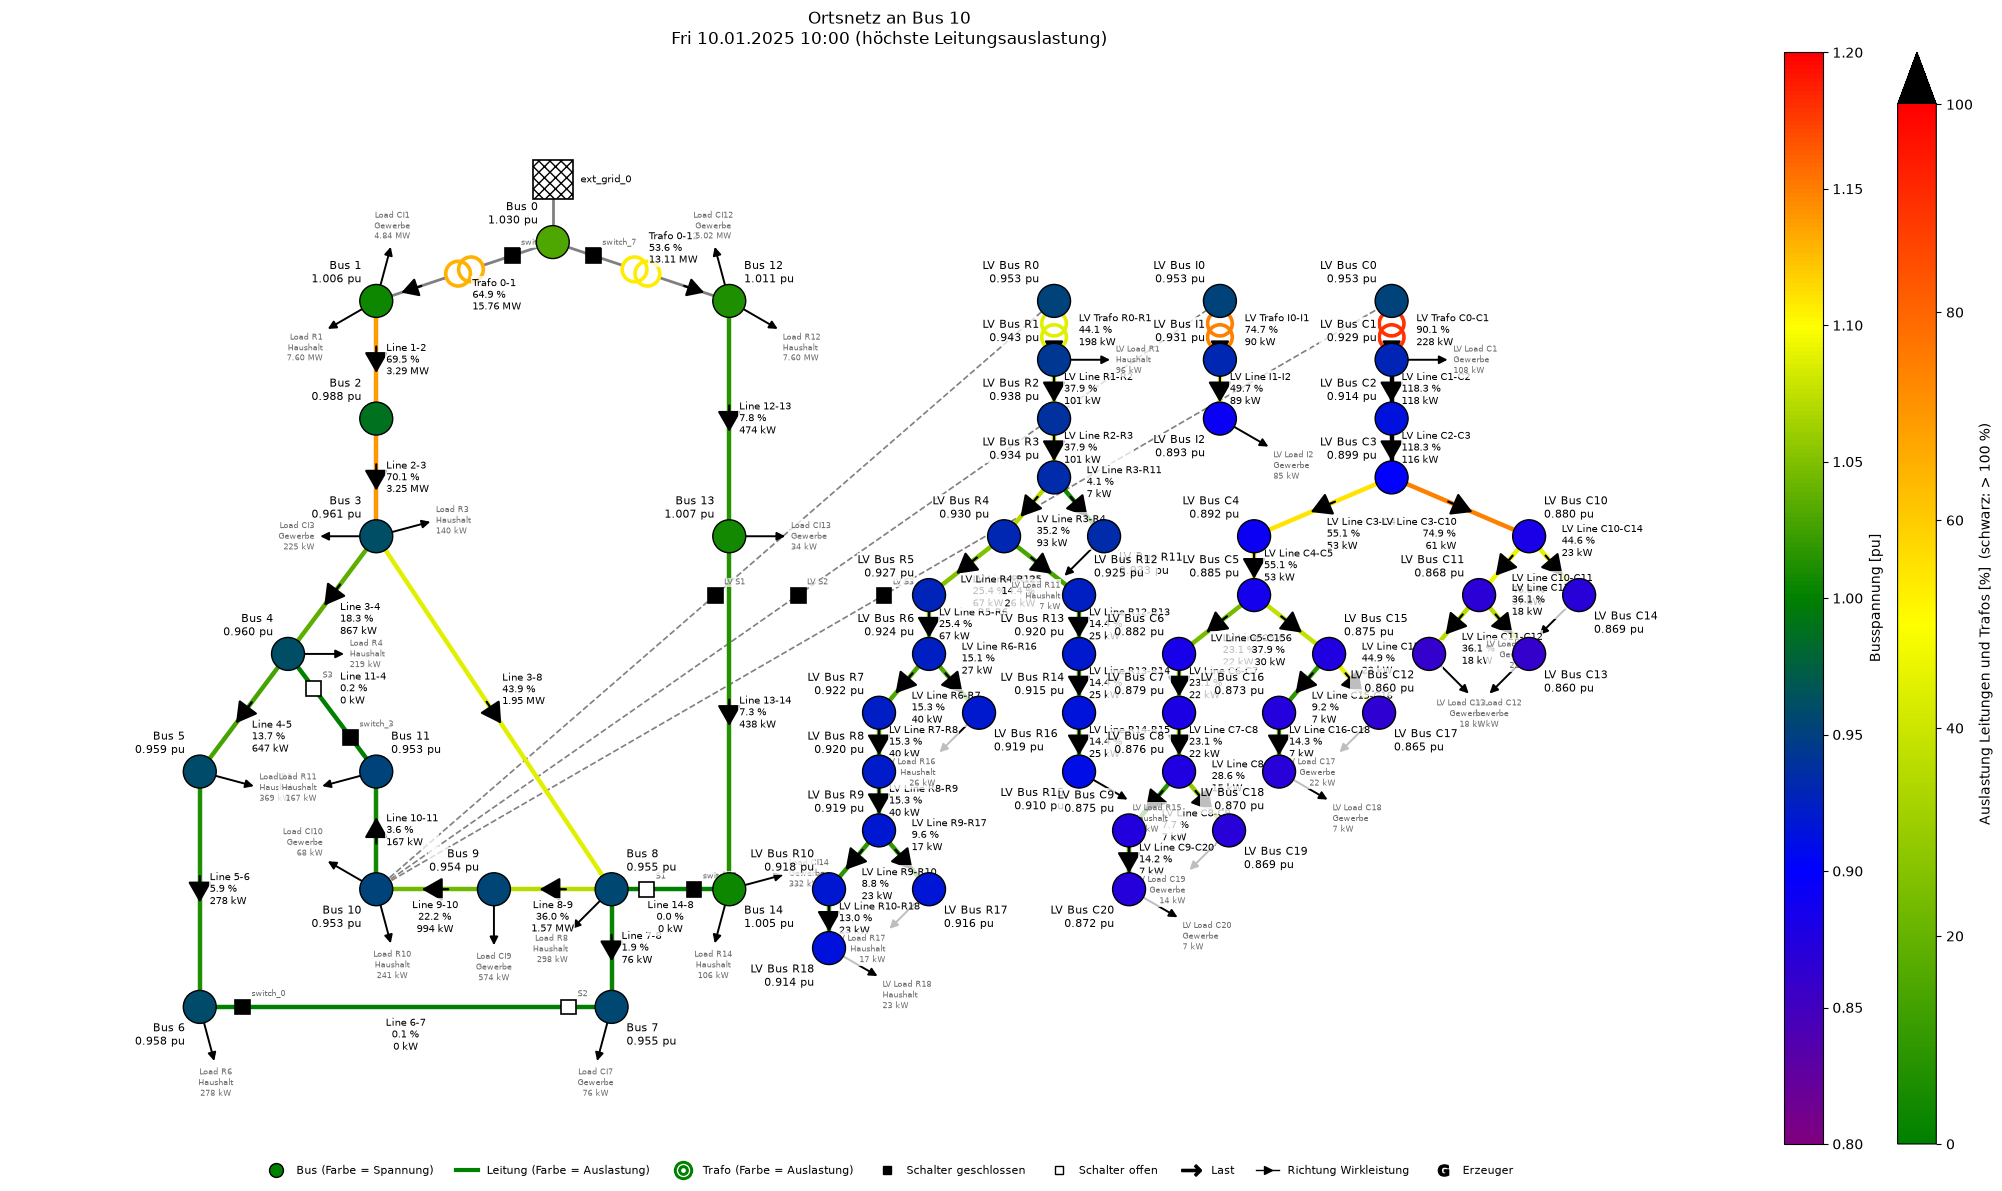

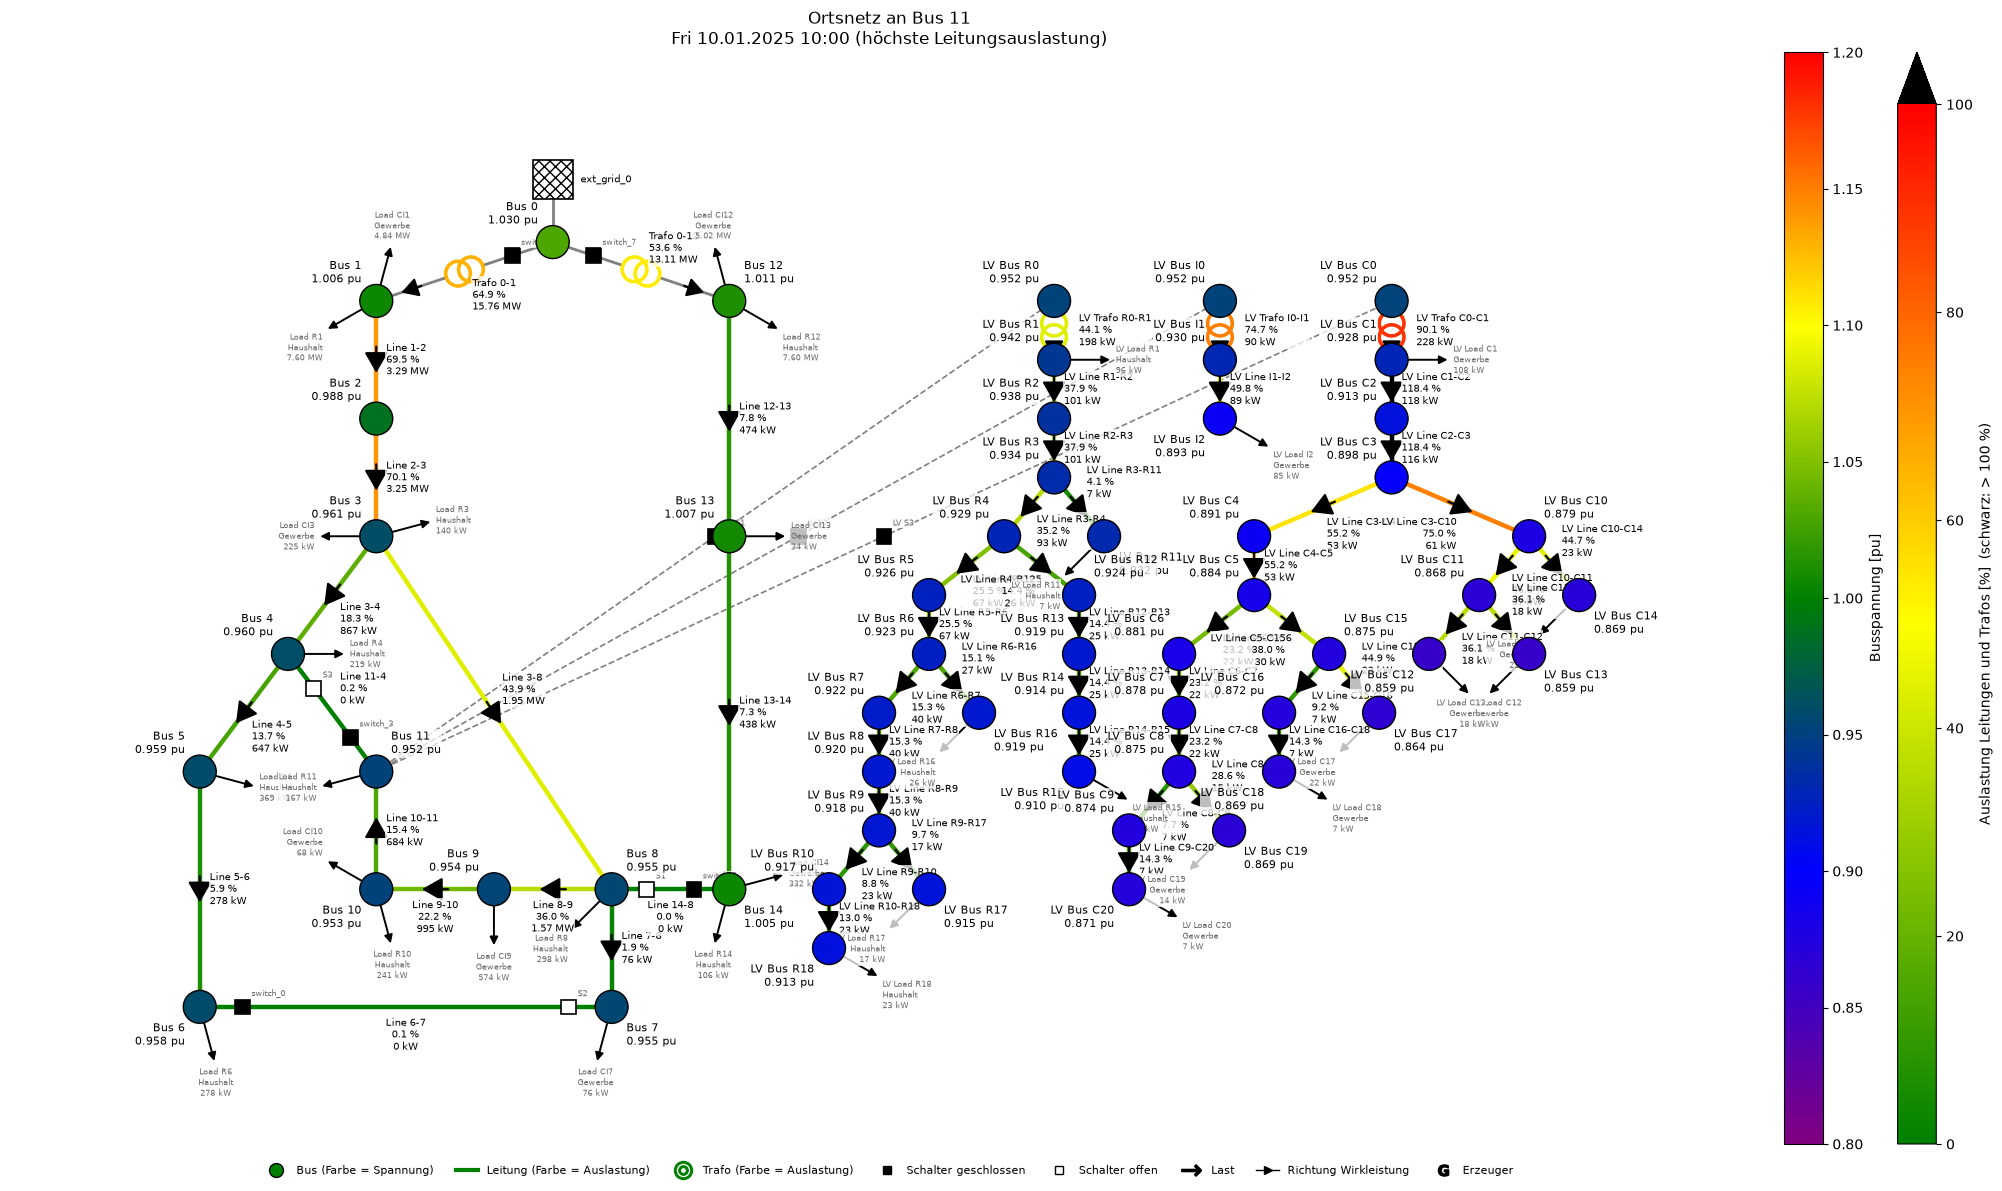

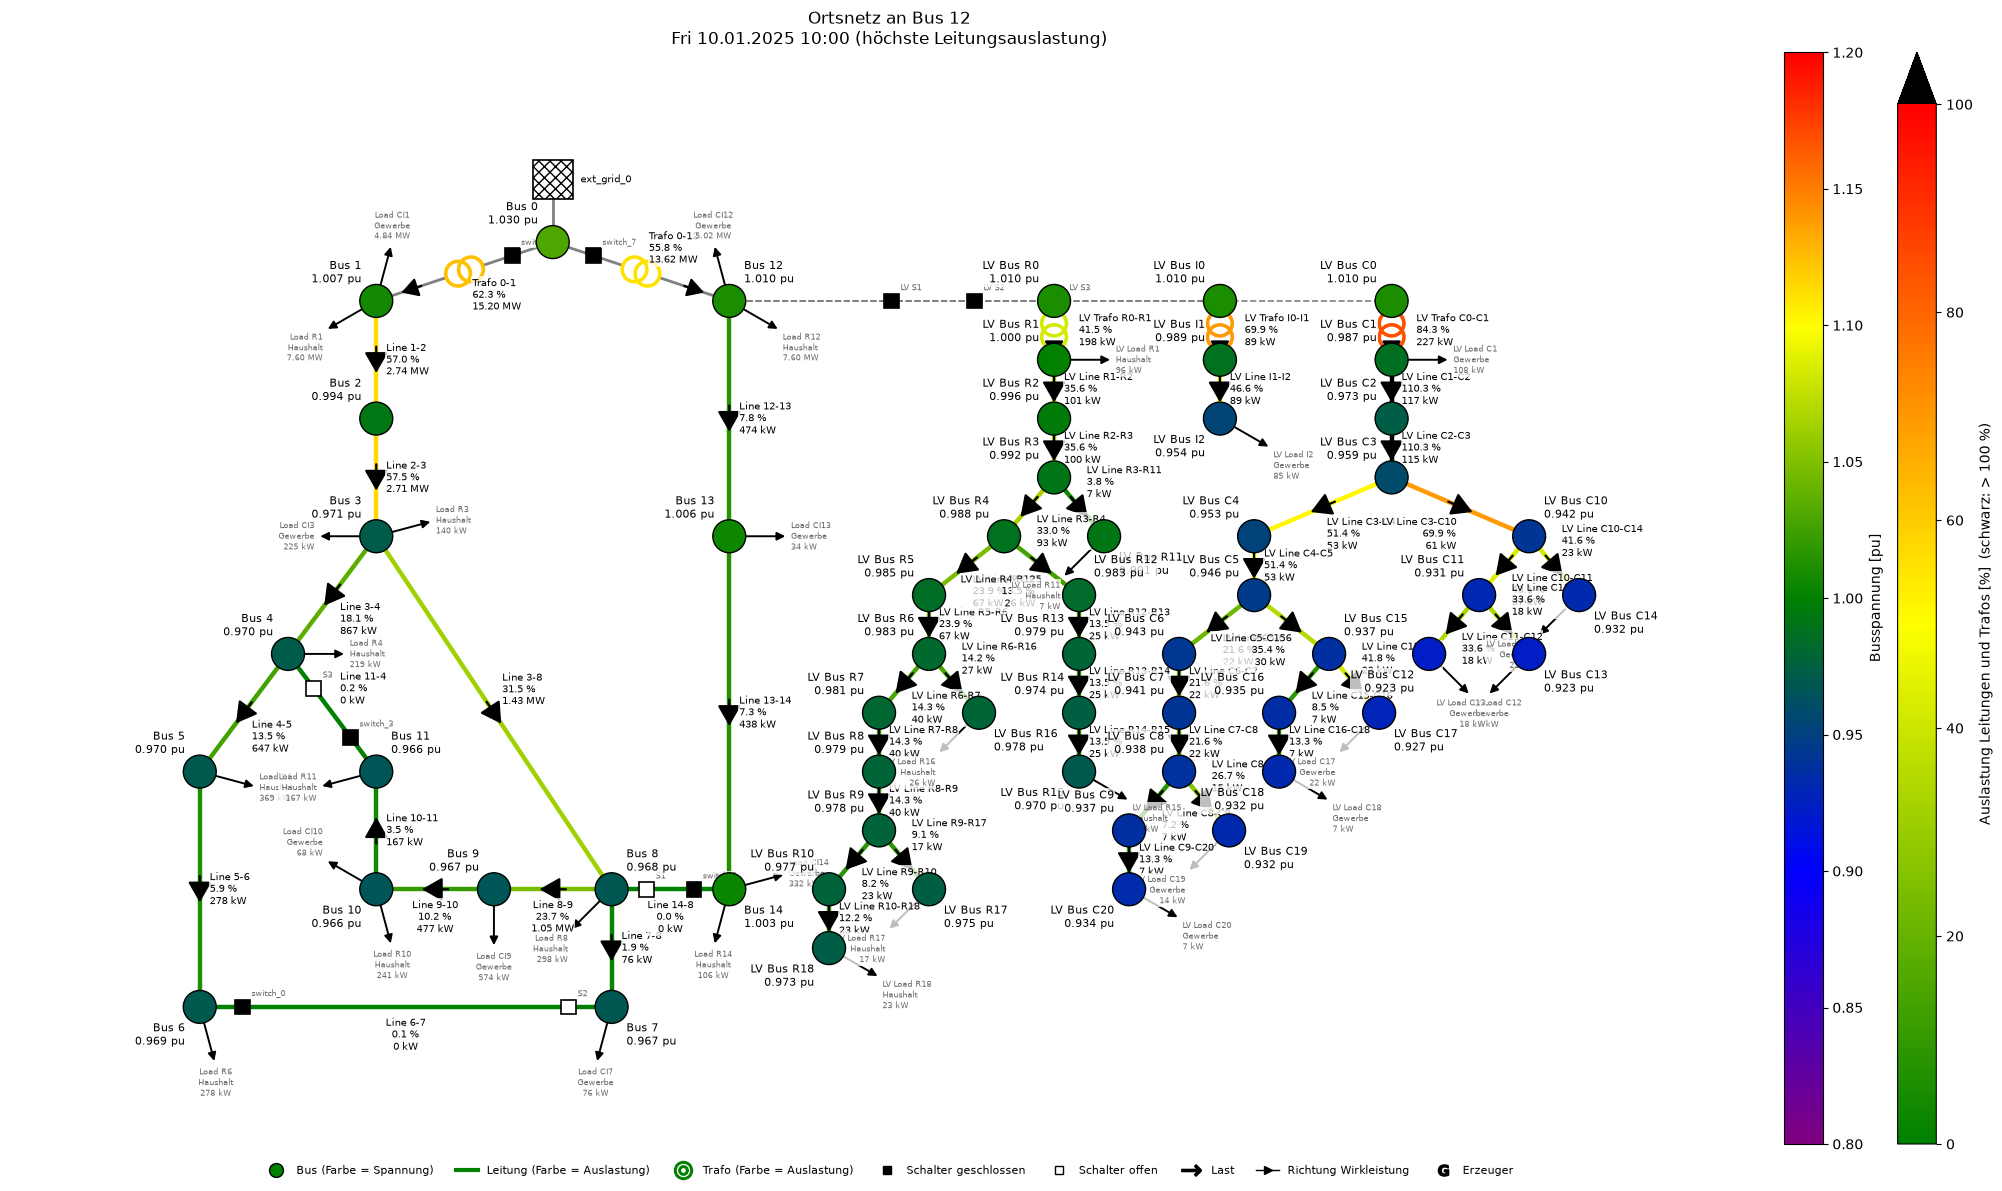

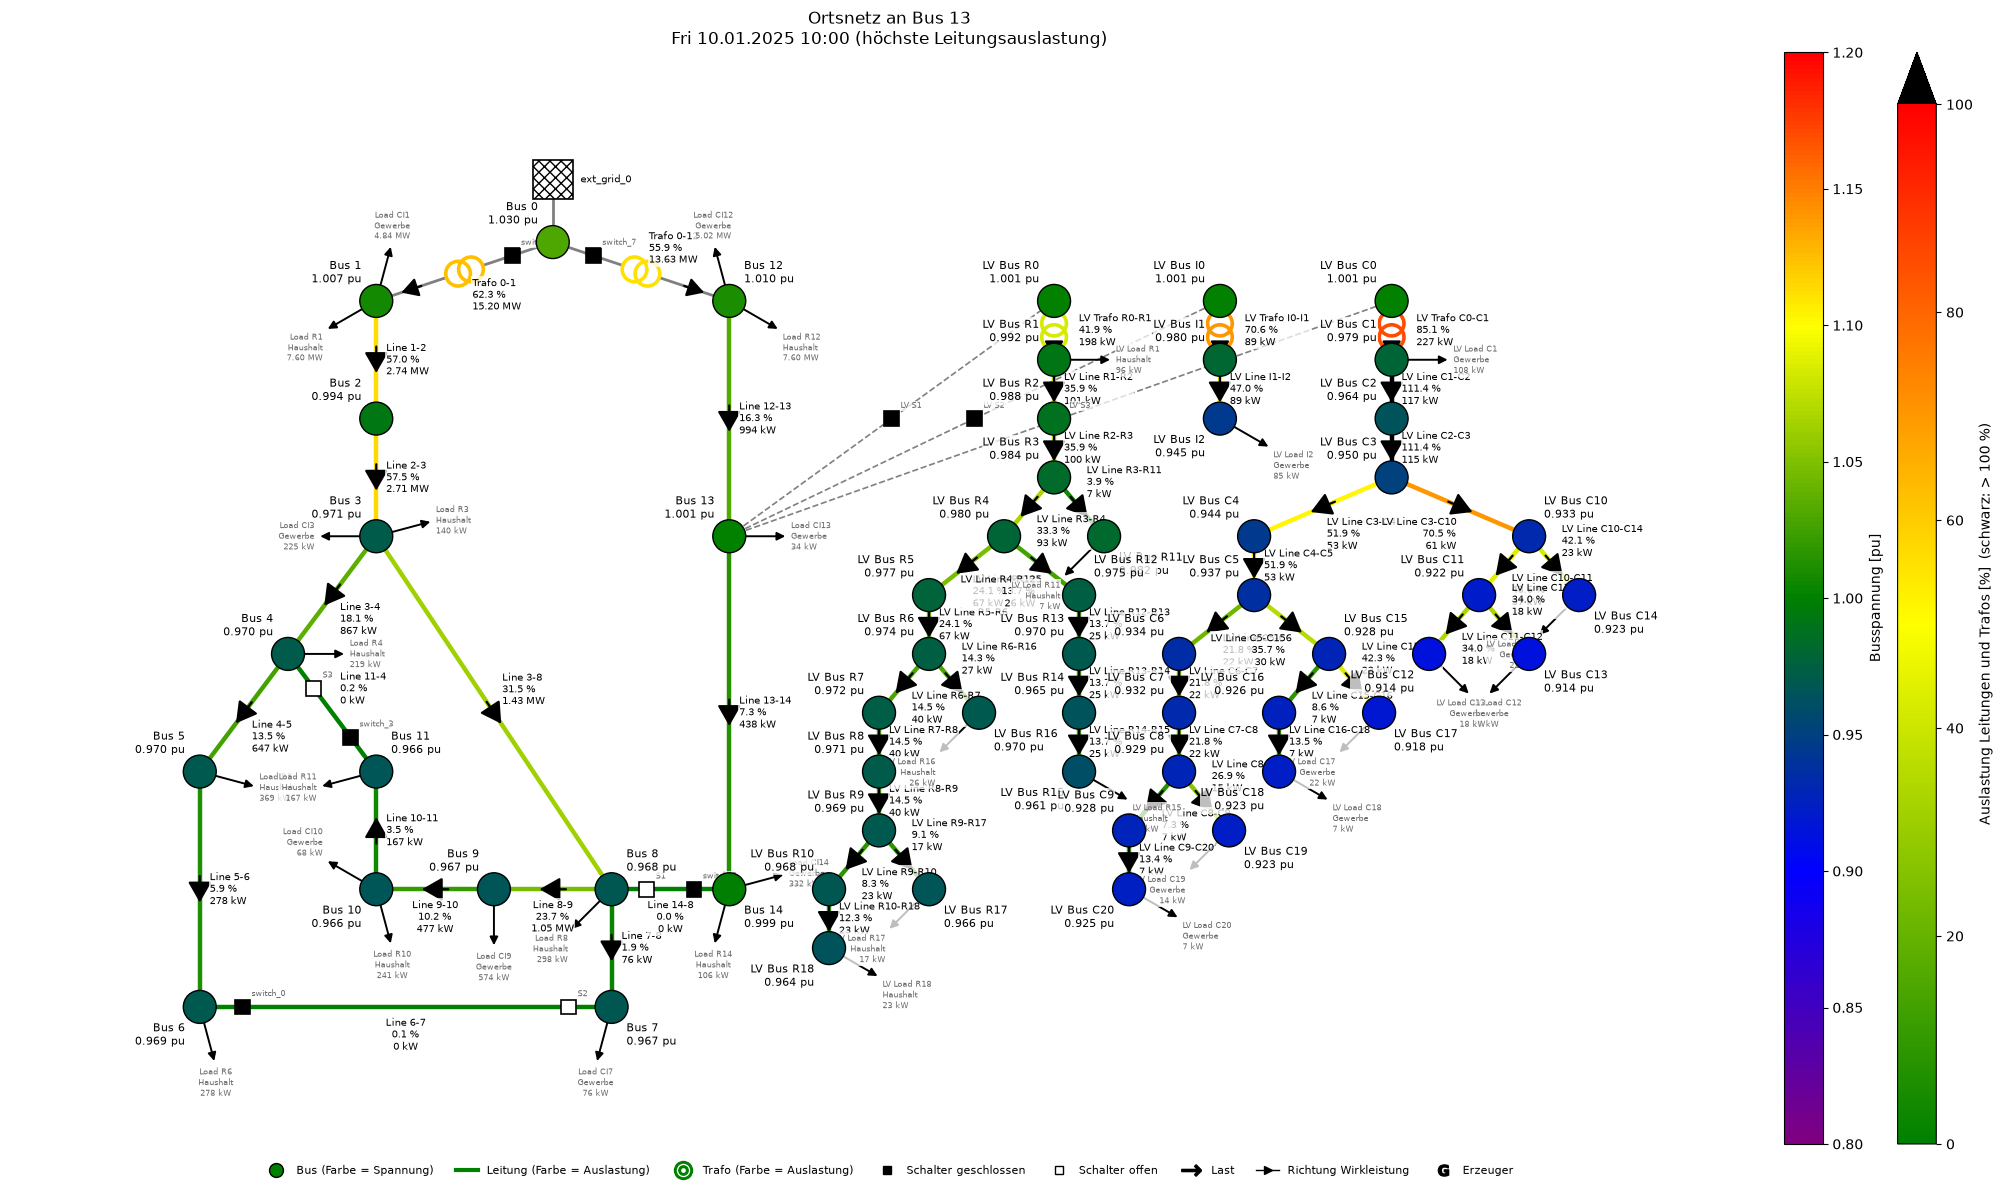

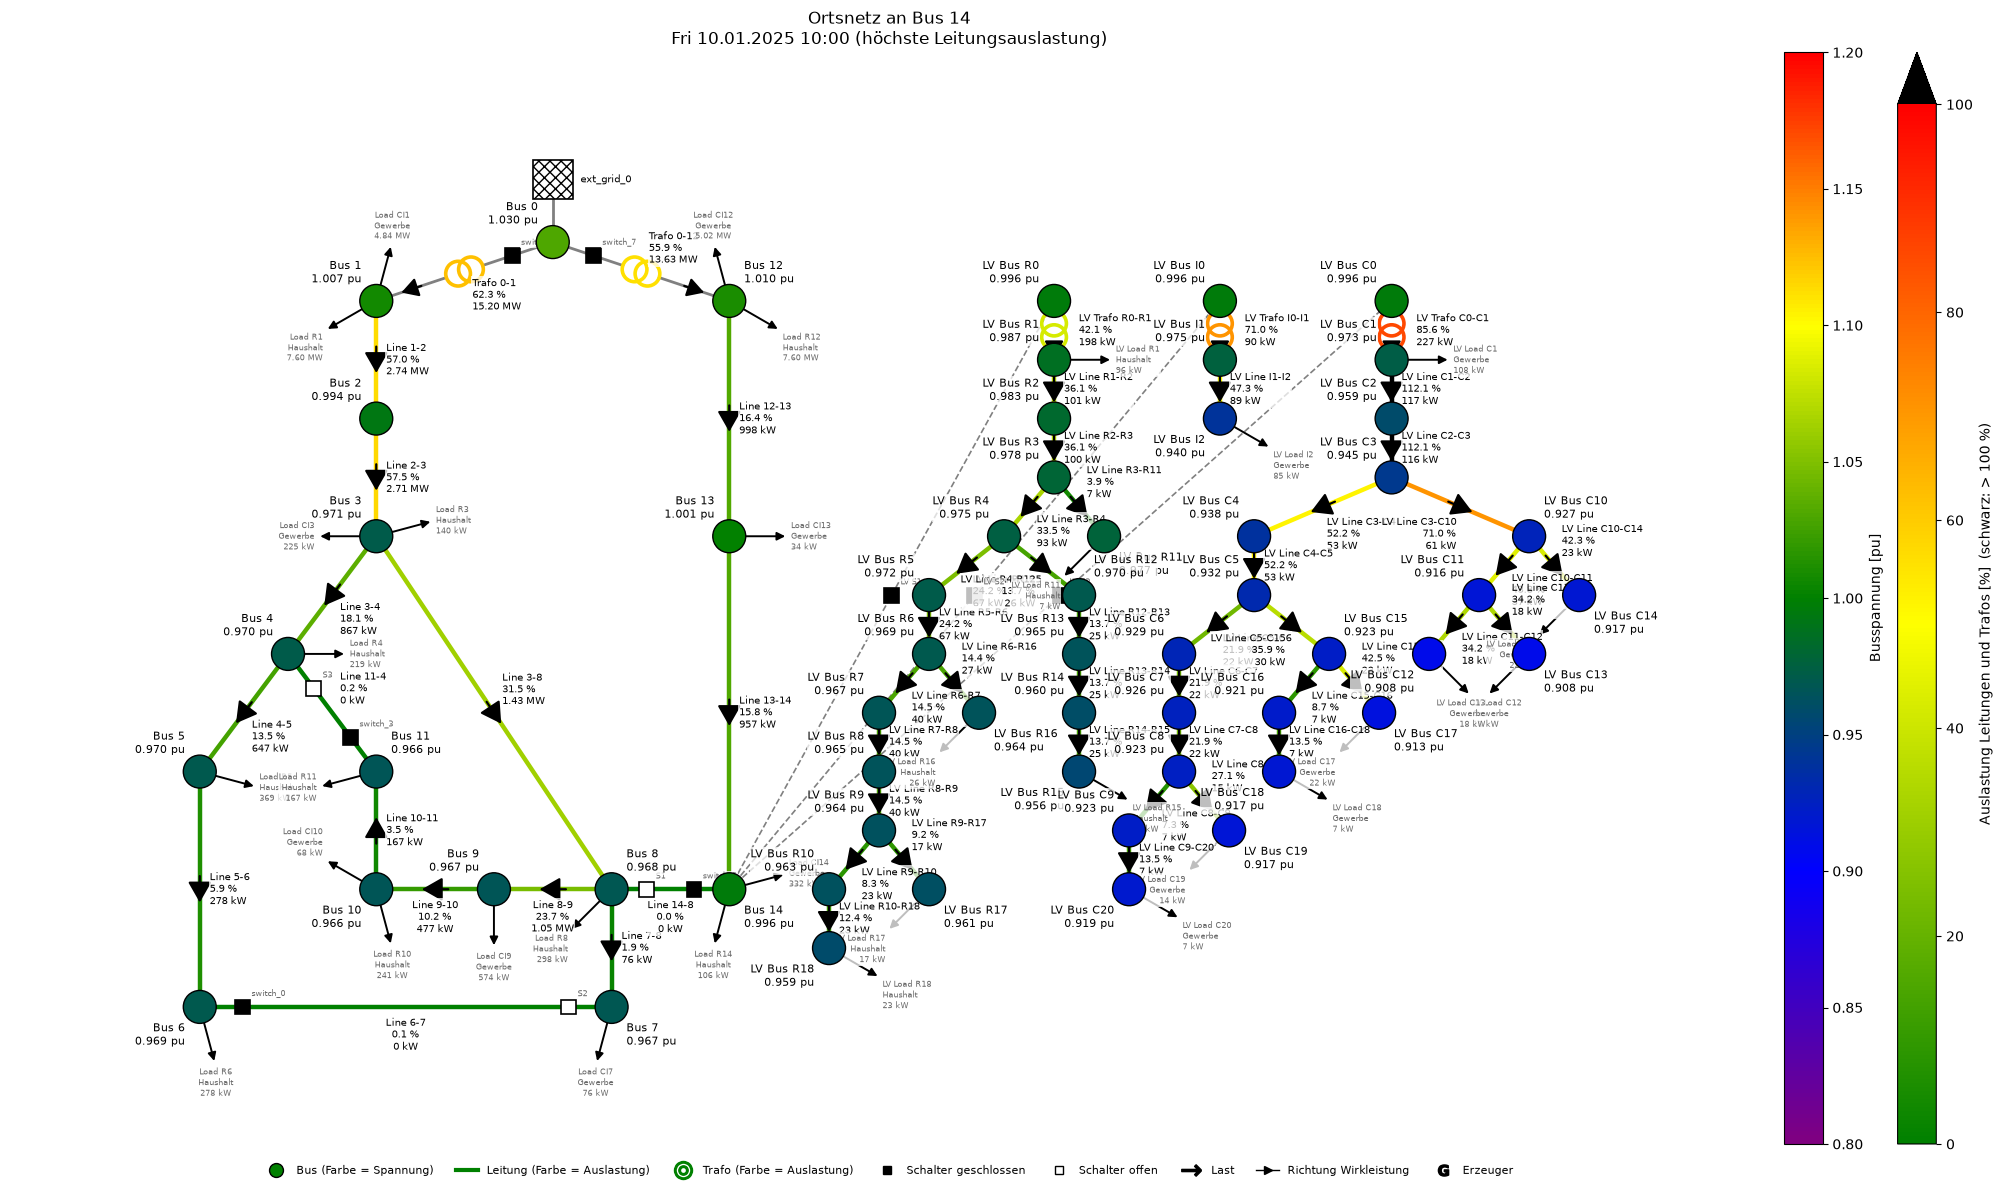

In [29]:
for at_bus, s in lv_sims.items():
    s.createDiagram(Diagram.NETWORK, time="max_loading", title=f"Ortsnetz an {at_bus}")

### Quellen

[13] K. Strunz et al., „Benchmark Systems for Network Integration of Renewable and Distributed Energy Resources“, CIGRE Task Force C6.04.02, Technical Brochure 575, Paris: CIGRE, 2014.

[14] L. Thurner et al., „pandapower – An Open-Source Python Tool for Convenient Modeling, Analysis, and Optimization of Electric Power Systems“, IEEE Transactions on Power Systems, Bd. 33, Nr. 6, S. 6510–6521, Nov. 2018, doi: 10.1109/TPWRS.2018.2829021.

[15] DIN EN 50160, „Merkmale der Spannung in öffentlichen Elektrizitätsversorgungsnetzen“ (EN 50160:2010 mit Änderungen), Berlin: Beuth.

[18] *Smart Energy Management for Smart Grid*, Basel: MDPI Books, Tabelle der Leitungstypen des CIGRE-LV-Netzes (Querschnitt, R und L von Phasen- und Neutralleiter, Bemessungsstrom). Online: https://mdpi-res.com/bookfiles/book/7980/Smart_Energy_Management_for_Smart_Grid.pdf

*Bei [18] Herausgeber, Jahr, Kapitel und Seite der Tabelle ergänzen.*